In [17]:
# Dataset
# https://www.kaggle.com/code/ginelledsouza/stroke-analysis

In [1]:
# Import Libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
sns.set_style("whitegrid")
plt.rcParams['figure.dpi'] = 120
RND = 2026  # random seed

# Load Data function
def Load_Data(path='healthcare-dataset-stroke-data.csv'):
    return pd.read_csv(path)

# Load the dataset
data = Load_Data('healthcare-dataset-stroke-data.csv')

# Remove rows where 'bmi' is missing and save to new file
data_clean = data.dropna(subset=['bmi'])
data_clean.to_csv('healthcare_dataset_stroke.csv', index=False)

# Reload the newly saved dataset
data = pd.read_csv('healthcare_dataset_stroke.csv')

# Check missing values & dataset overview
def overview(df):
    print("Rows / Columns:", df.shape)
    print("\nColumn types:\n", df.dtypes)
    print("\nMissing values per column:\n", df.isna().sum())
    print("\nDescriptive summary (numeric columns):\n", df.describe().T)

overview(data)

print("\nDuplicate rows count:", data.duplicated().sum())

# Display the first few rows (Jupyter will format this cleanly)
data.head()

Rows / Columns: (4909, 12)

Column types:
 id                     int64
gender                   str
age                  float64
hypertension           int64
heart_disease          int64
ever_married             str
work_type                str
Residence_type           str
avg_glucose_level    float64
bmi                  float64
smoking_status           str
stroke                 int64
dtype: object

Missing values per column:
 id                   0
gender               0
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_type       0
avg_glucose_level    0
bmi                  0
smoking_status       0
stroke               0
dtype: int64

Descriptive summary (numeric columns):
                     count          mean           std    min       25%  \
id                 4909.0  37064.313506  20995.098457  77.00  18605.00   
age                4909.0     42.865374     22.555115   0.08     25.00   
hypertension  

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
2,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
3,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1
4,56669,Male,81.0,0,0,Yes,Private,Urban,186.21,29.0,formerly smoked,1


# Exploratory Stroke Data Analysis

C:\Users\HP\AppData\Local\Temp\ipykernel_14664\3187583630.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(
C:\Users\HP\AppData\Local\Temp\ipykernel_14664\3187583630.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(
C:\Users\HP\AppData\Local\Temp\ipykernel_14664\3187583630.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(
C:\Users\HP\AppData\Local\Temp\ipykernel_14664\3187583630.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` an

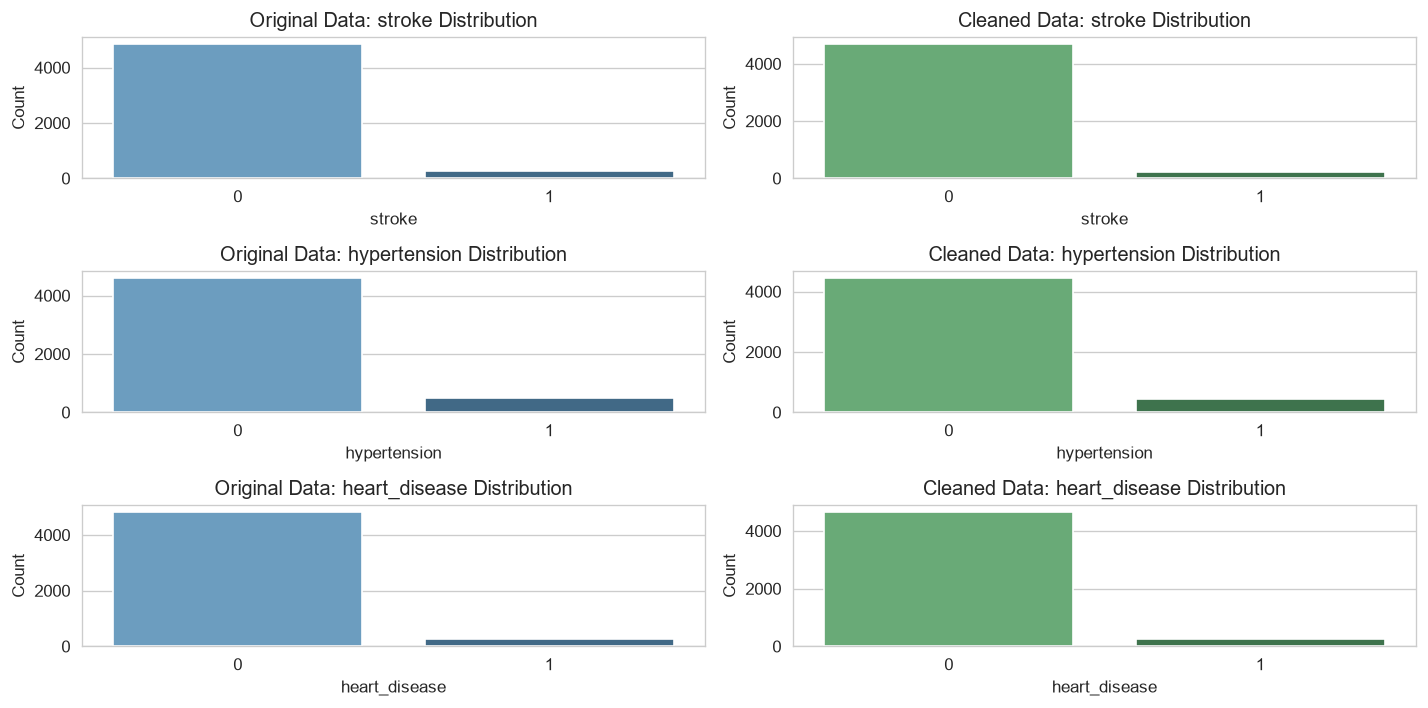

--- Original Target Class Ratio (%) ---
stroke
0    95.127202
1     4.872798
Name: proportion, dtype: float64

--- Cleaned Target Class Ratio (%) ---
stroke
0    95.742514
1     4.257486
Name: proportion, dtype: float64


In [2]:
# Both Datasets
df_clean = Load_Data(path='healthcare_dataset_stroke.csv')
df_original = pd.read_csv('healthcare-dataset-stroke-data.csv')
# Define target variable and key categorical features to compare
features = ['stroke', 'hypertension', 'heart_disease']

fig, axes = plt.subplots(len(features), 2, figsize=(12, 2 * len(features)))

for i, feature in enumerate(features):
    # Plot Original Data Distribution
    sns.countplot(
        data=df_original, 
        x=feature, 
        ax=axes[i, 0], 
        palette='Blues_d'
    )
    axes[i, 0].set_title(f'Original Data: {feature} Distribution')
    axes[i, 0].set_xlabel(feature)
    axes[i, 0].set_ylabel('Count')

    # Plot Cleaned Data Distribution
    sns.countplot(
        data=df_clean, 
        x=feature, 
        ax=axes[i, 1], 
        palette='Greens_d'
    )
    axes[i, 1].set_title(f'Cleaned Data: {feature} Distribution')
    axes[i, 1].set_xlabel(feature)
    axes[i, 1].set_ylabel('Count')

plt.tight_layout()
plt.show()

# Print exact class proportion percentages for comparison
print("--- Original Target Class Ratio (%) ---")
print(df_original['stroke'].value_counts(normalize=True) * 100)

print("\n--- Cleaned Target Class Ratio (%) ---")
print(df_clean['stroke'].value_counts(normalize=True) * 100)


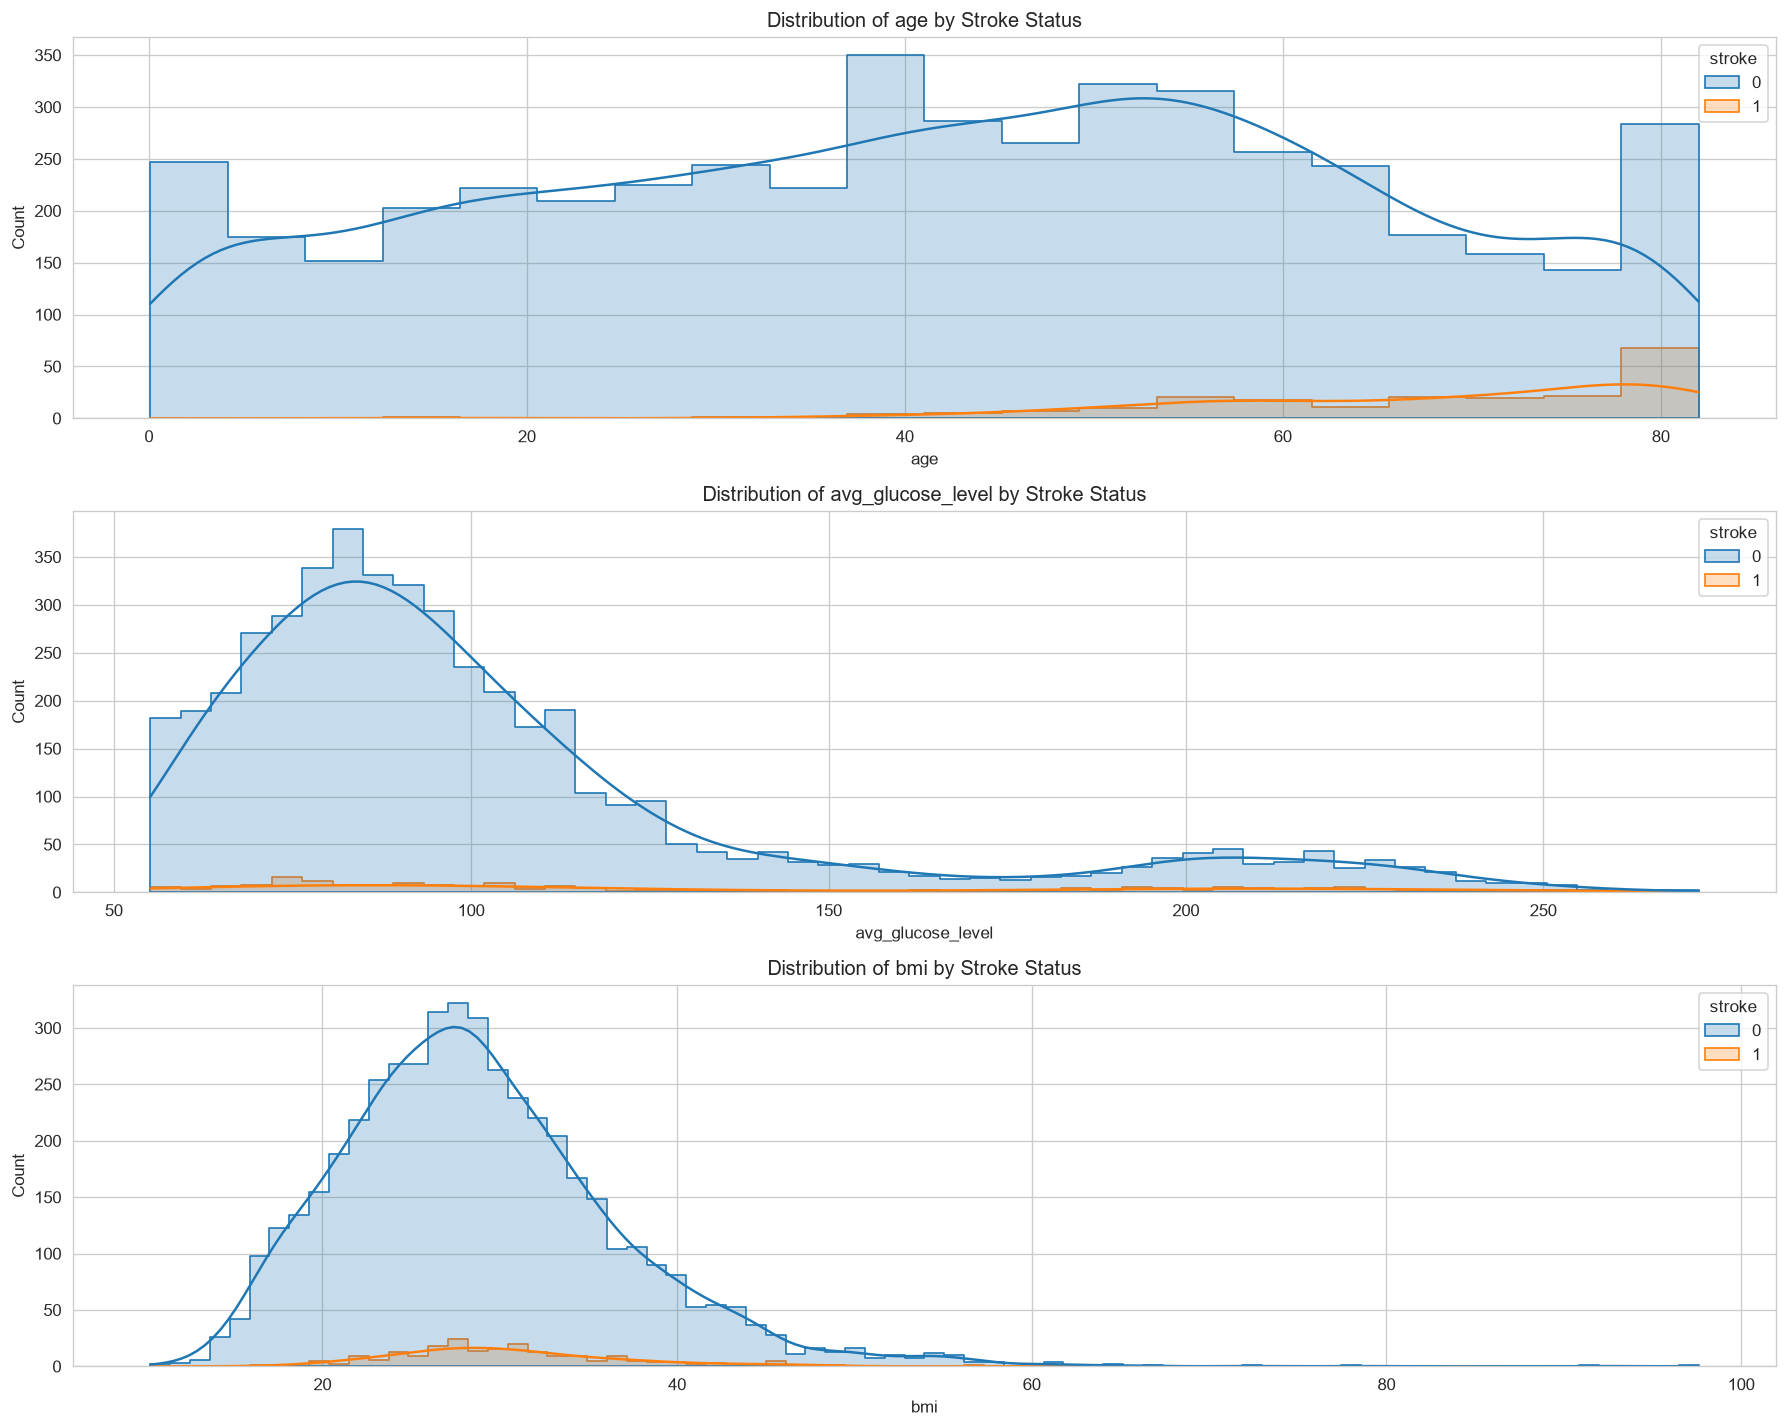

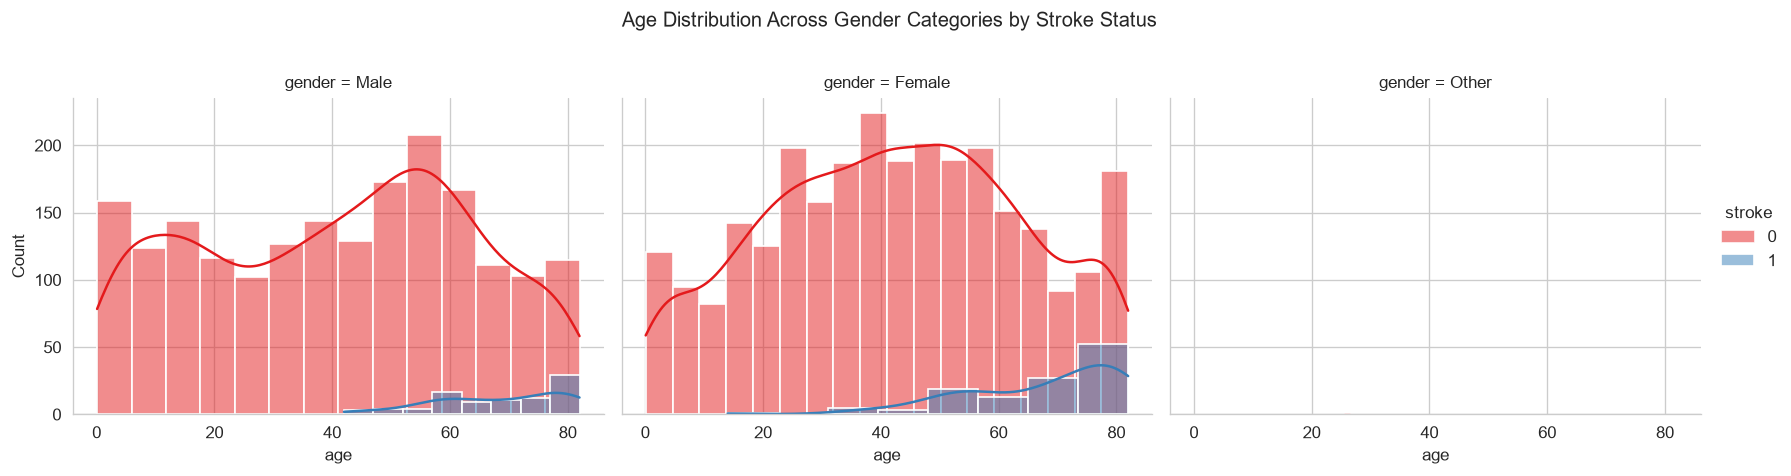

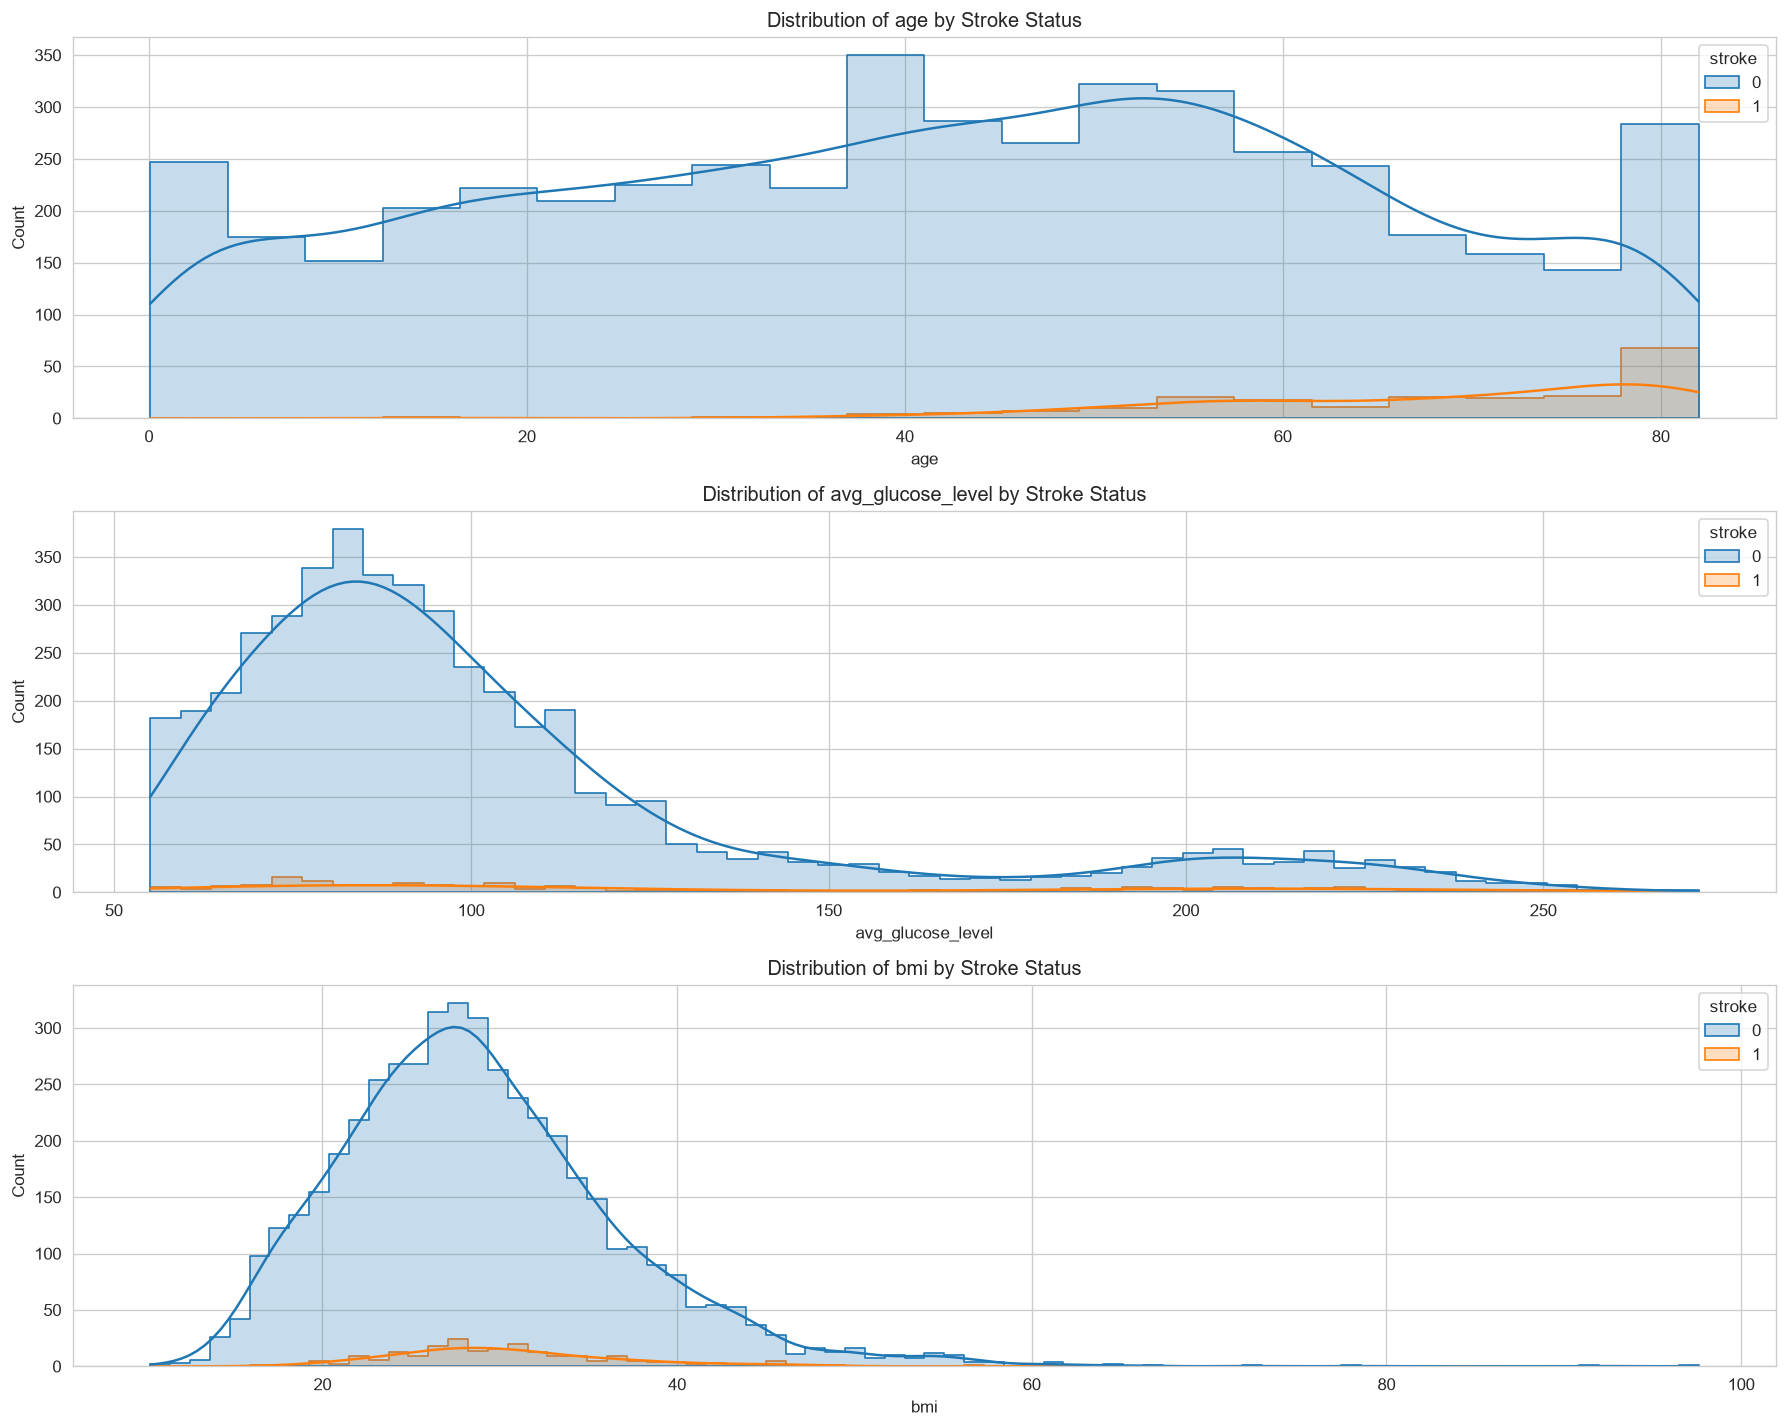

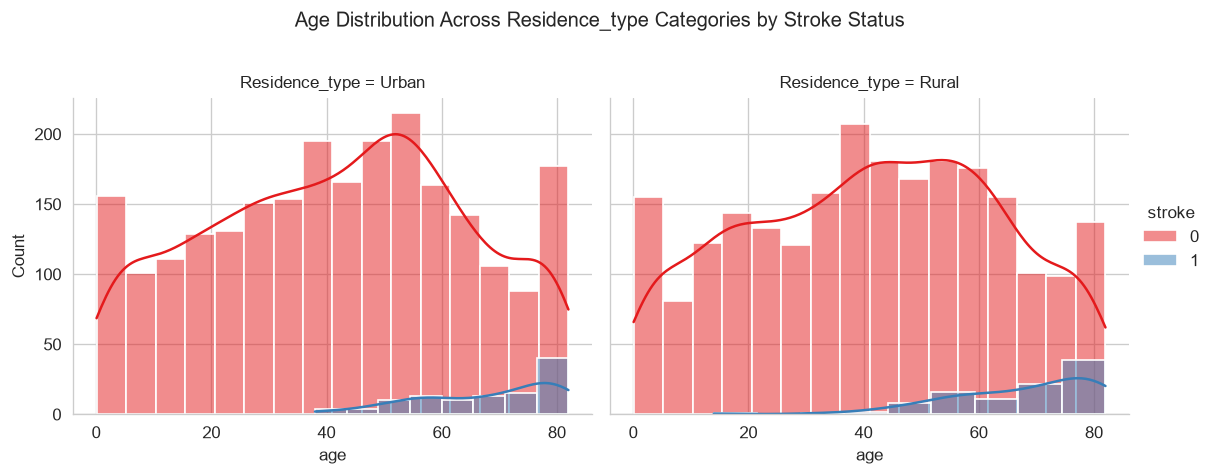

In [3]:
# Distribution plots for numerical features by Gender, Residence Type, and Stroke status
num_cols = ['age', 'avg_glucose_level', 'bmi']
categorical_groups = ['gender', 'Residence_type']

def grid_histograms_by_group(df, num_cols, cat_groups):
    for cat in cat_groups:
        # Plot distributions for each numerical feature split by stroke status
        plt.figure(figsize=(15, 4 * len(num_cols)))
        for i, col in enumerate(num_cols, 1):
            plt.subplot(len(num_cols), 1, i)
            sns.histplot(
                data=df, 
                x=col, 
                hue='stroke', 
                kde=True, 
                element='step',
                common_norm=False
            )
            plt.title(f'Distribution of {col} by Stroke Status')
        plt.tight_layout()
        plt.show()

        # Detailed breakdown across Gender/Residence Type categories and Stroke
        g = sns.FacetGrid(df, col=cat, hue='stroke', height=4, aspect=1.2, palette='Set1')
        g.map_dataframe(sns.histplot, x='age', kde=True, alpha=0.5)
        g.add_legend()
        g.fig.subplots_adjust(top=0.8)
        g.fig.suptitle(f'Age Distribution Across {cat.capitalize()} Categories by Stroke Status')
        plt.show()

# Execute function in cell
grid_histograms_by_group(data, num_cols, categorical_groups)

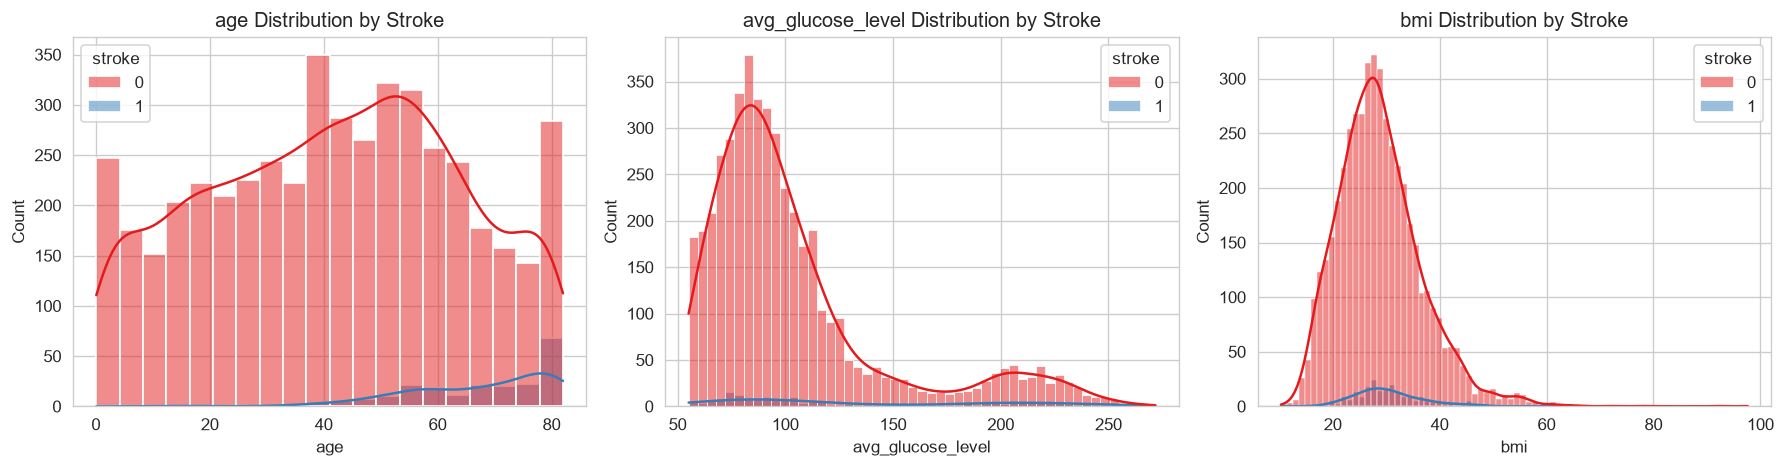

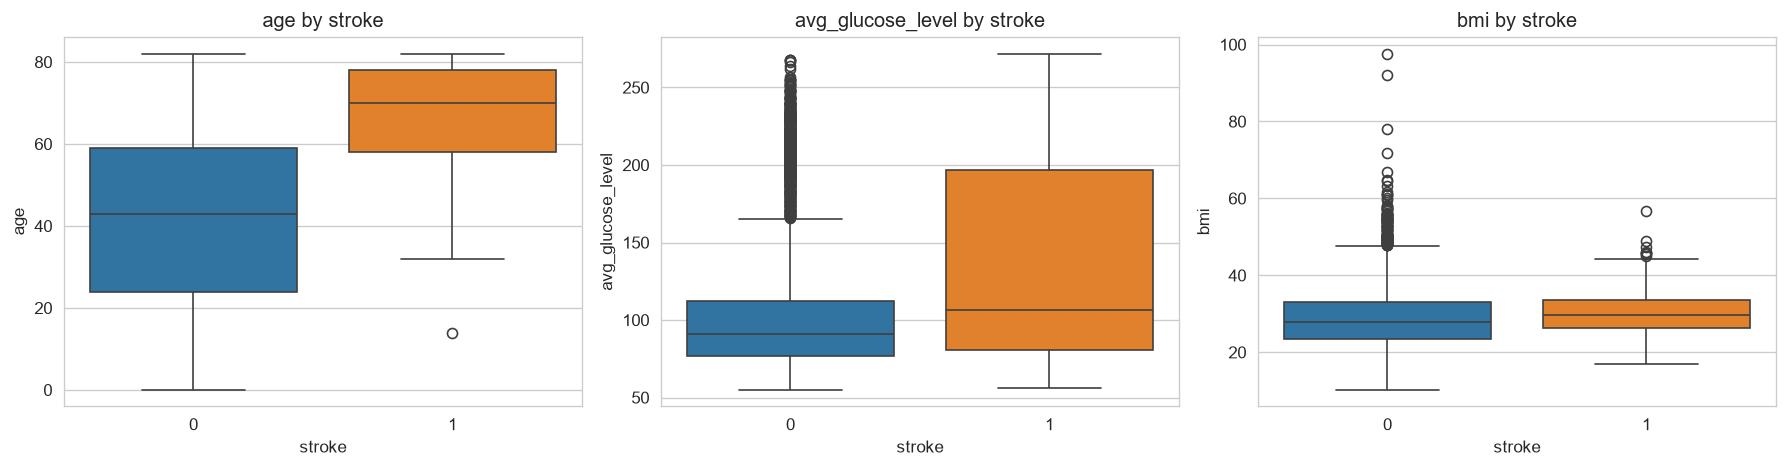

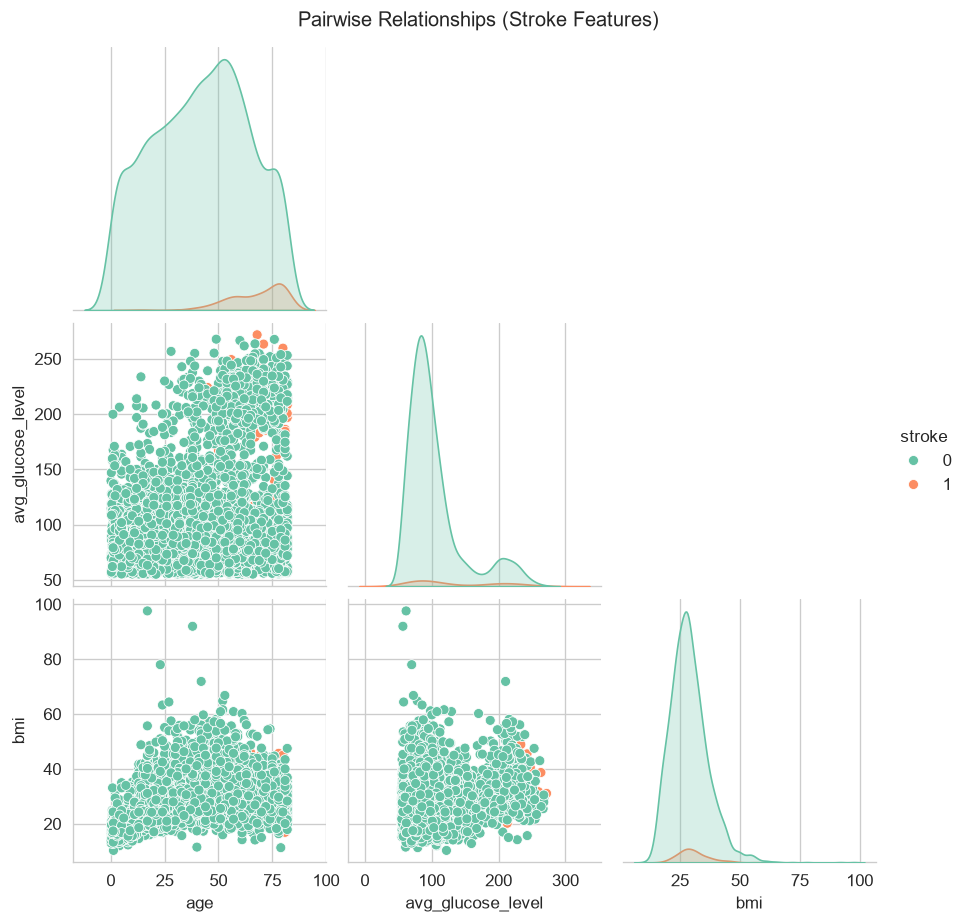

c:\Users\HP\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\numpy\_core\fromnumeric.py:4270: RuntimeWarning: Degrees of freedom <= 0 for slice
  return _methods._var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
c:\Users\HP\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\numpy\_core\_methods.py:211: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
c:\Users\HP\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\numpy\_core\_methods.py:219: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


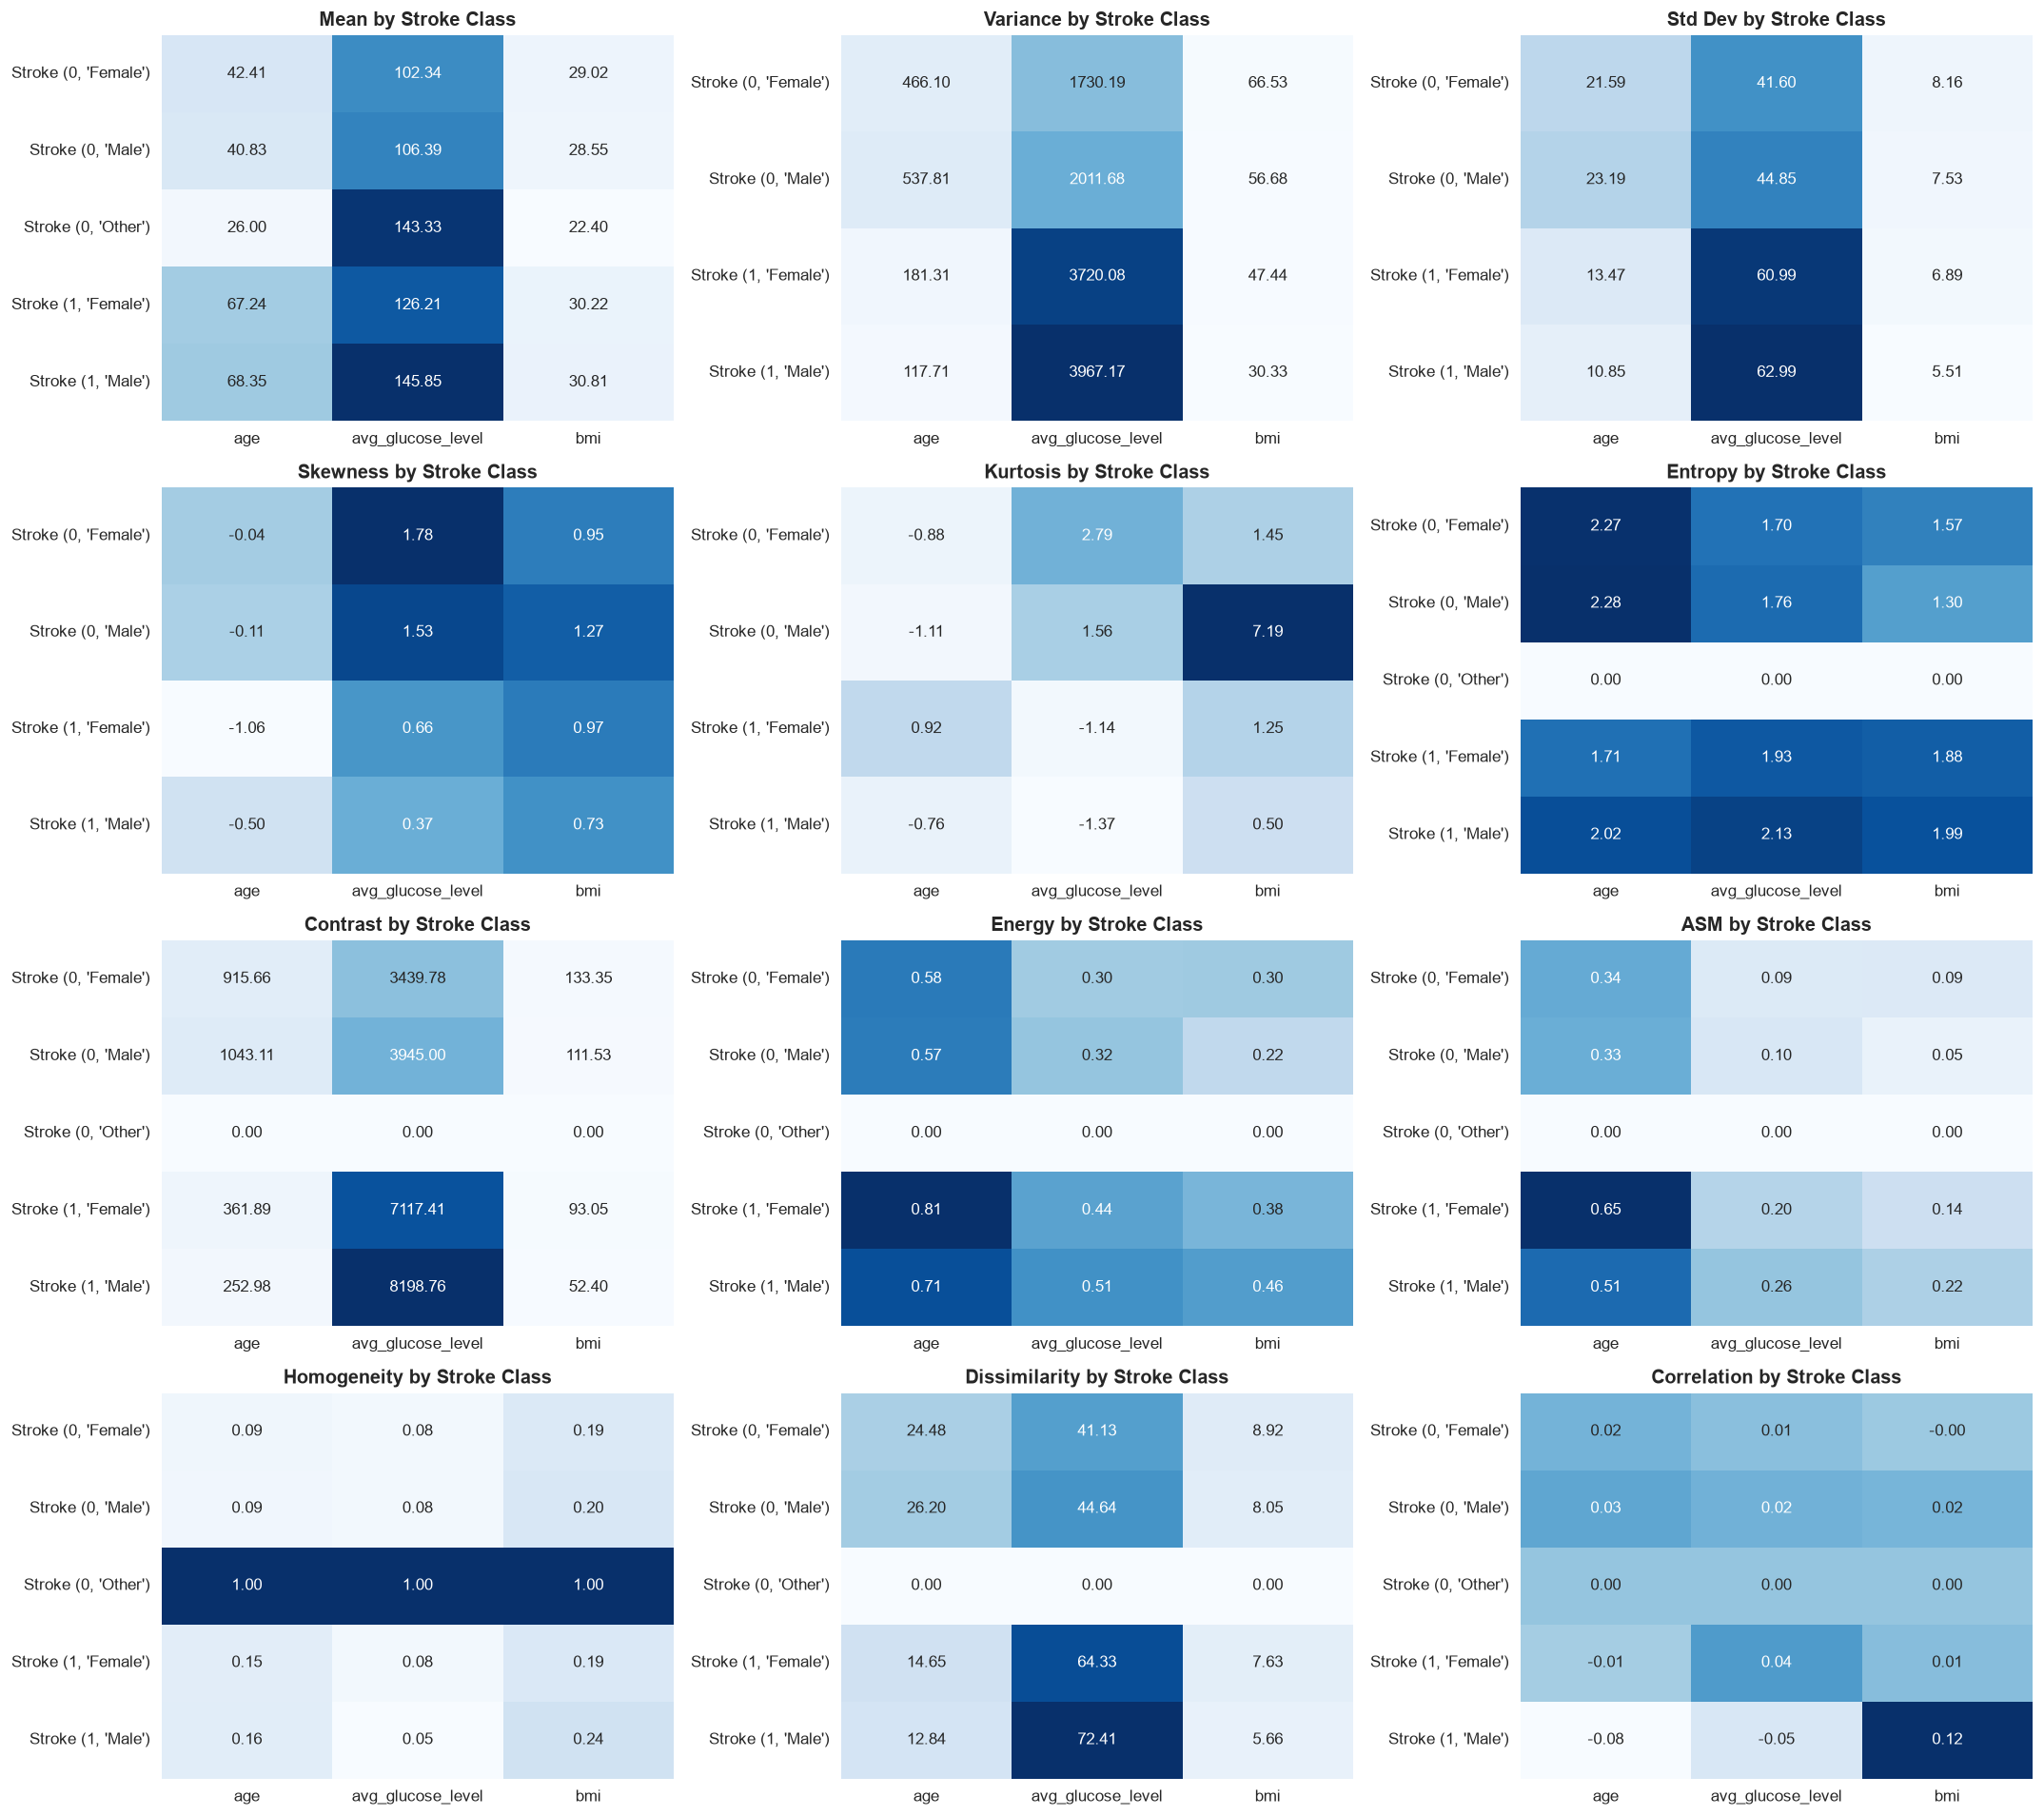

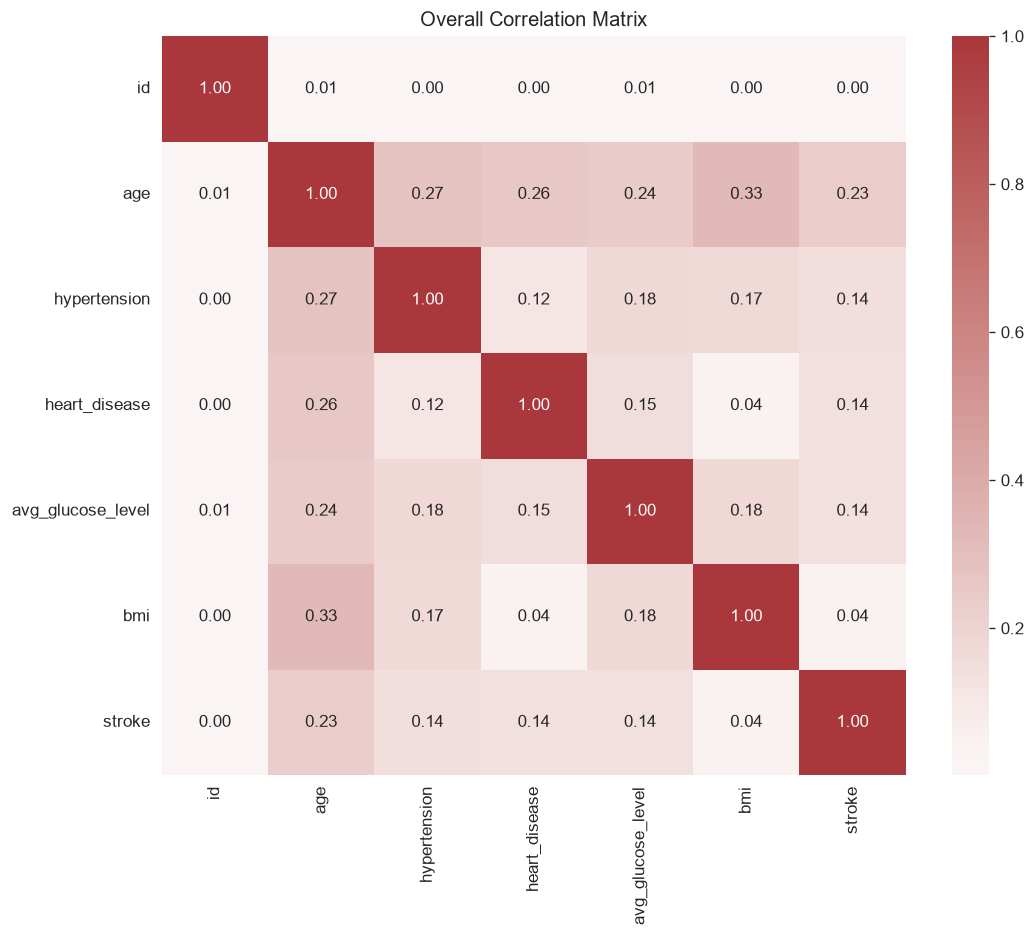

In [4]:
from scipy.stats import skew, kurtosis, entropy

# Select continuous numerical columns
num_cols_temp = ['age', 'avg_glucose_level', 'bmi']

# 1. Distribution Histograms grouped by stroke status
plt.figure(figsize=(15, 4))
for i, col in enumerate(num_cols_temp, 1):
    plt.subplot(1, 3, i)

    classes = data['stroke'].unique()
    can_use_kde = all(data[data['stroke'] == c][col].nunique() > 1 for c in classes)

    sns.histplot(data, x=col, hue='stroke', kde=can_use_kde, palette='Set1', alpha=0.5)
    plt.title(f'{col} Distribution by Stroke')
plt.tight_layout()
plt.show()

# 2. Boxplots grouped by stroke class
def boxplots_by_label(df, features, label='stroke'):
    plt.figure(figsize=(15, 4))
    for i, f in enumerate(features, 1):
        plt.subplot(1, 3, i)
        sns.boxplot(x=label, y=f, data=df, hue=label, palette=['#1f77b4', '#ff7f0e'], legend=False)
        plt.title(f'{f} by {label}')
    plt.tight_layout()
    plt.show()

boxplots_by_label(data, num_cols_temp)

# 3. Pairwise Relationships
df_pair = data[num_cols_temp + ["stroke"]]

sns.pairplot(
    df_pair,
    hue="stroke",
    corner=True,
    palette="Set2"
)
plt.suptitle("Pairwise Relationships (Stroke Features)", y=1.02)
plt.show()

# 4. Detailed Statistical and Texture/Signal Analysis by Stroke Class
def compute_class_stats(df, num_cols, label='stroke'):
    records = []
    ### grouped = df.groupby(label)
    grouped = df.groupby([label, 'gender'])
    
    for stroke_val, group in grouped:
        for col in num_cols:
            vals = group[col].dropna().values
            if len(vals) == 0:
                continue
            
            # Statistical Metrics
            m = np.mean(vals)
            var = np.var(vals, ddof=1)
            std = np.std(vals, ddof=1)
            sk = skew(vals)
            kt = kurtosis(vals)
            
            # Entropy
            hist, _ = np.histogram(vals, bins=10, density=True)
            hist = hist[hist > 0]
            ent = entropy(hist)
            
            # Signal / Distribution Proxies (Contrast, Dissimilarity, ASM, Energy, Homogeneity, Correlation)
            contrast = np.mean(np.diff(vals)**2) if len(vals) > 1 else 0
            dissimilarity = np.mean(np.abs(np.diff(vals))) if len(vals) > 1 else 0
            
            vals_norm = (vals - vals.min()) / (vals.max() - vals.min() + 1e-8)
            asm = np.sum(vals_norm**2) / len(vals_norm)
            energy = np.sqrt(asm)
            
            homogeneity = np.mean(1.0 / (1.0 + np.abs(np.diff(vals)))) if len(vals) > 1 else 1.0
            
            corr = pd.Series(vals).autocorr(lag=1) if len(vals) > 1 else 0.0
            if np.isnan(corr):
                corr = 0.0

            records.append({
                'Stroke': f'Stroke {stroke_val}',
                'Feature': col,
                'Mean': m,
                'Variance': var,
                'Std Dev': std,
                'Skewness': sk,
                'Kurtosis': kt,
                'Entropy': ent,
                'Contrast': contrast,
                'Energy': energy,
                'ASM': asm,
                'Homogeneity': homogeneity,
                'Dissimilarity': dissimilarity,
                'Correlation': corr
            })
            
    return pd.DataFrame(records)

df_stats = compute_class_stats(data, num_cols_temp)

metrics = ['Mean', 'Variance', 'Std Dev', 'Skewness', 'Kurtosis', 'Entropy', 
           'Contrast', 'Energy', 'ASM', 'Homogeneity', 'Dissimilarity', 'Correlation']

fig, axes = plt.subplots(4, 3, figsize=(18, 16))
axes = axes.flatten()

for idx, metric in enumerate(metrics):
    pivot_df = df_stats.pivot_table(index='Stroke', columns='Feature', values=metric)
    sns.heatmap(pivot_df, annot=True, fmt=".2f", cmap="Blues", ax=axes[idx], cbar=False)
    axes[idx].set_title(f'{metric} by Stroke Class', fontsize=12, fontweight='bold')
    axes[idx].set_xlabel('')
    axes[idx].set_ylabel('')

plt.tight_layout()
plt.show()

# Full Correlation Matrix at the End
def corr_heatmap(df):
    corr = df.corr(numeric_only=True)
    plt.figure(figsize=(10, 8))
    sns.heatmap(corr, annot=True, fmt=".2f", cmap='vlag', center=0)
    plt.title('Overall Correlation Matrix')
    plt.show()

corr_heatmap(data)

C:\Users\HP\AppData\Local\Temp\ipykernel_14664\1652156649.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='stroke', y=col, data=data, palette='Set3', inner='quartile')
C:\Users\HP\AppData\Local\Temp\ipykernel_14664\1652156649.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='stroke', y=col, data=data, palette='Set3', inner='quartile')
C:\Users\HP\AppData\Local\Temp\ipykernel_14664\1652156649.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='stroke', y=col, data=data, palette='Set3', inner='quartile')


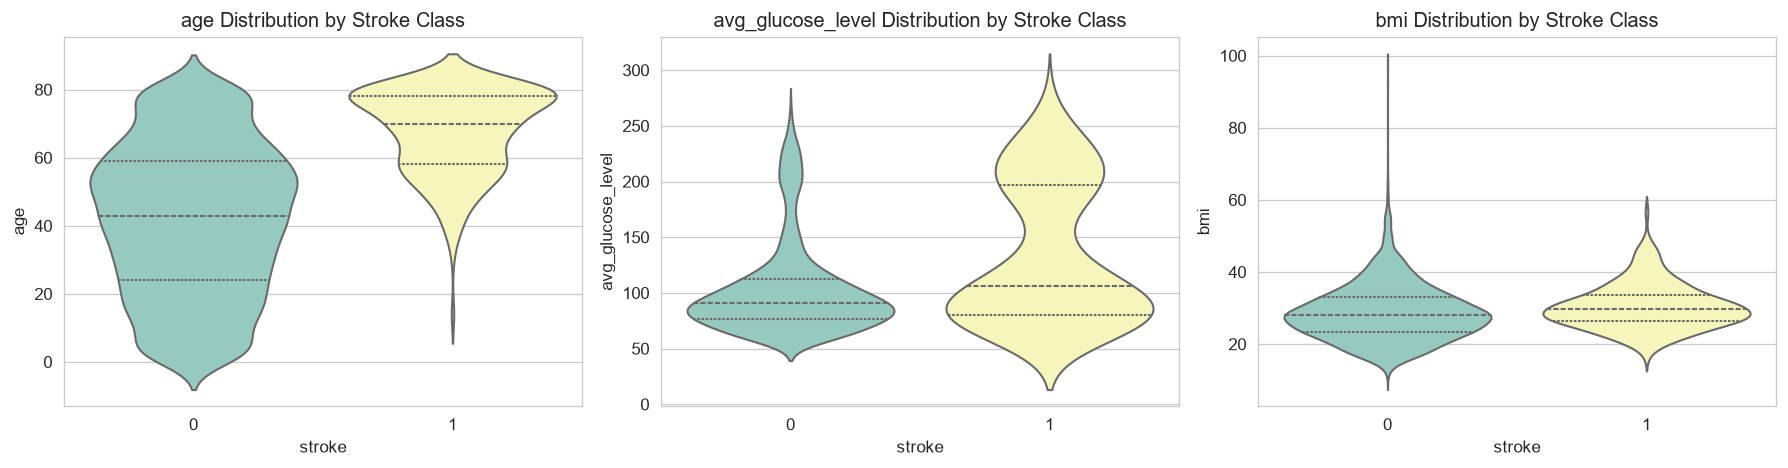

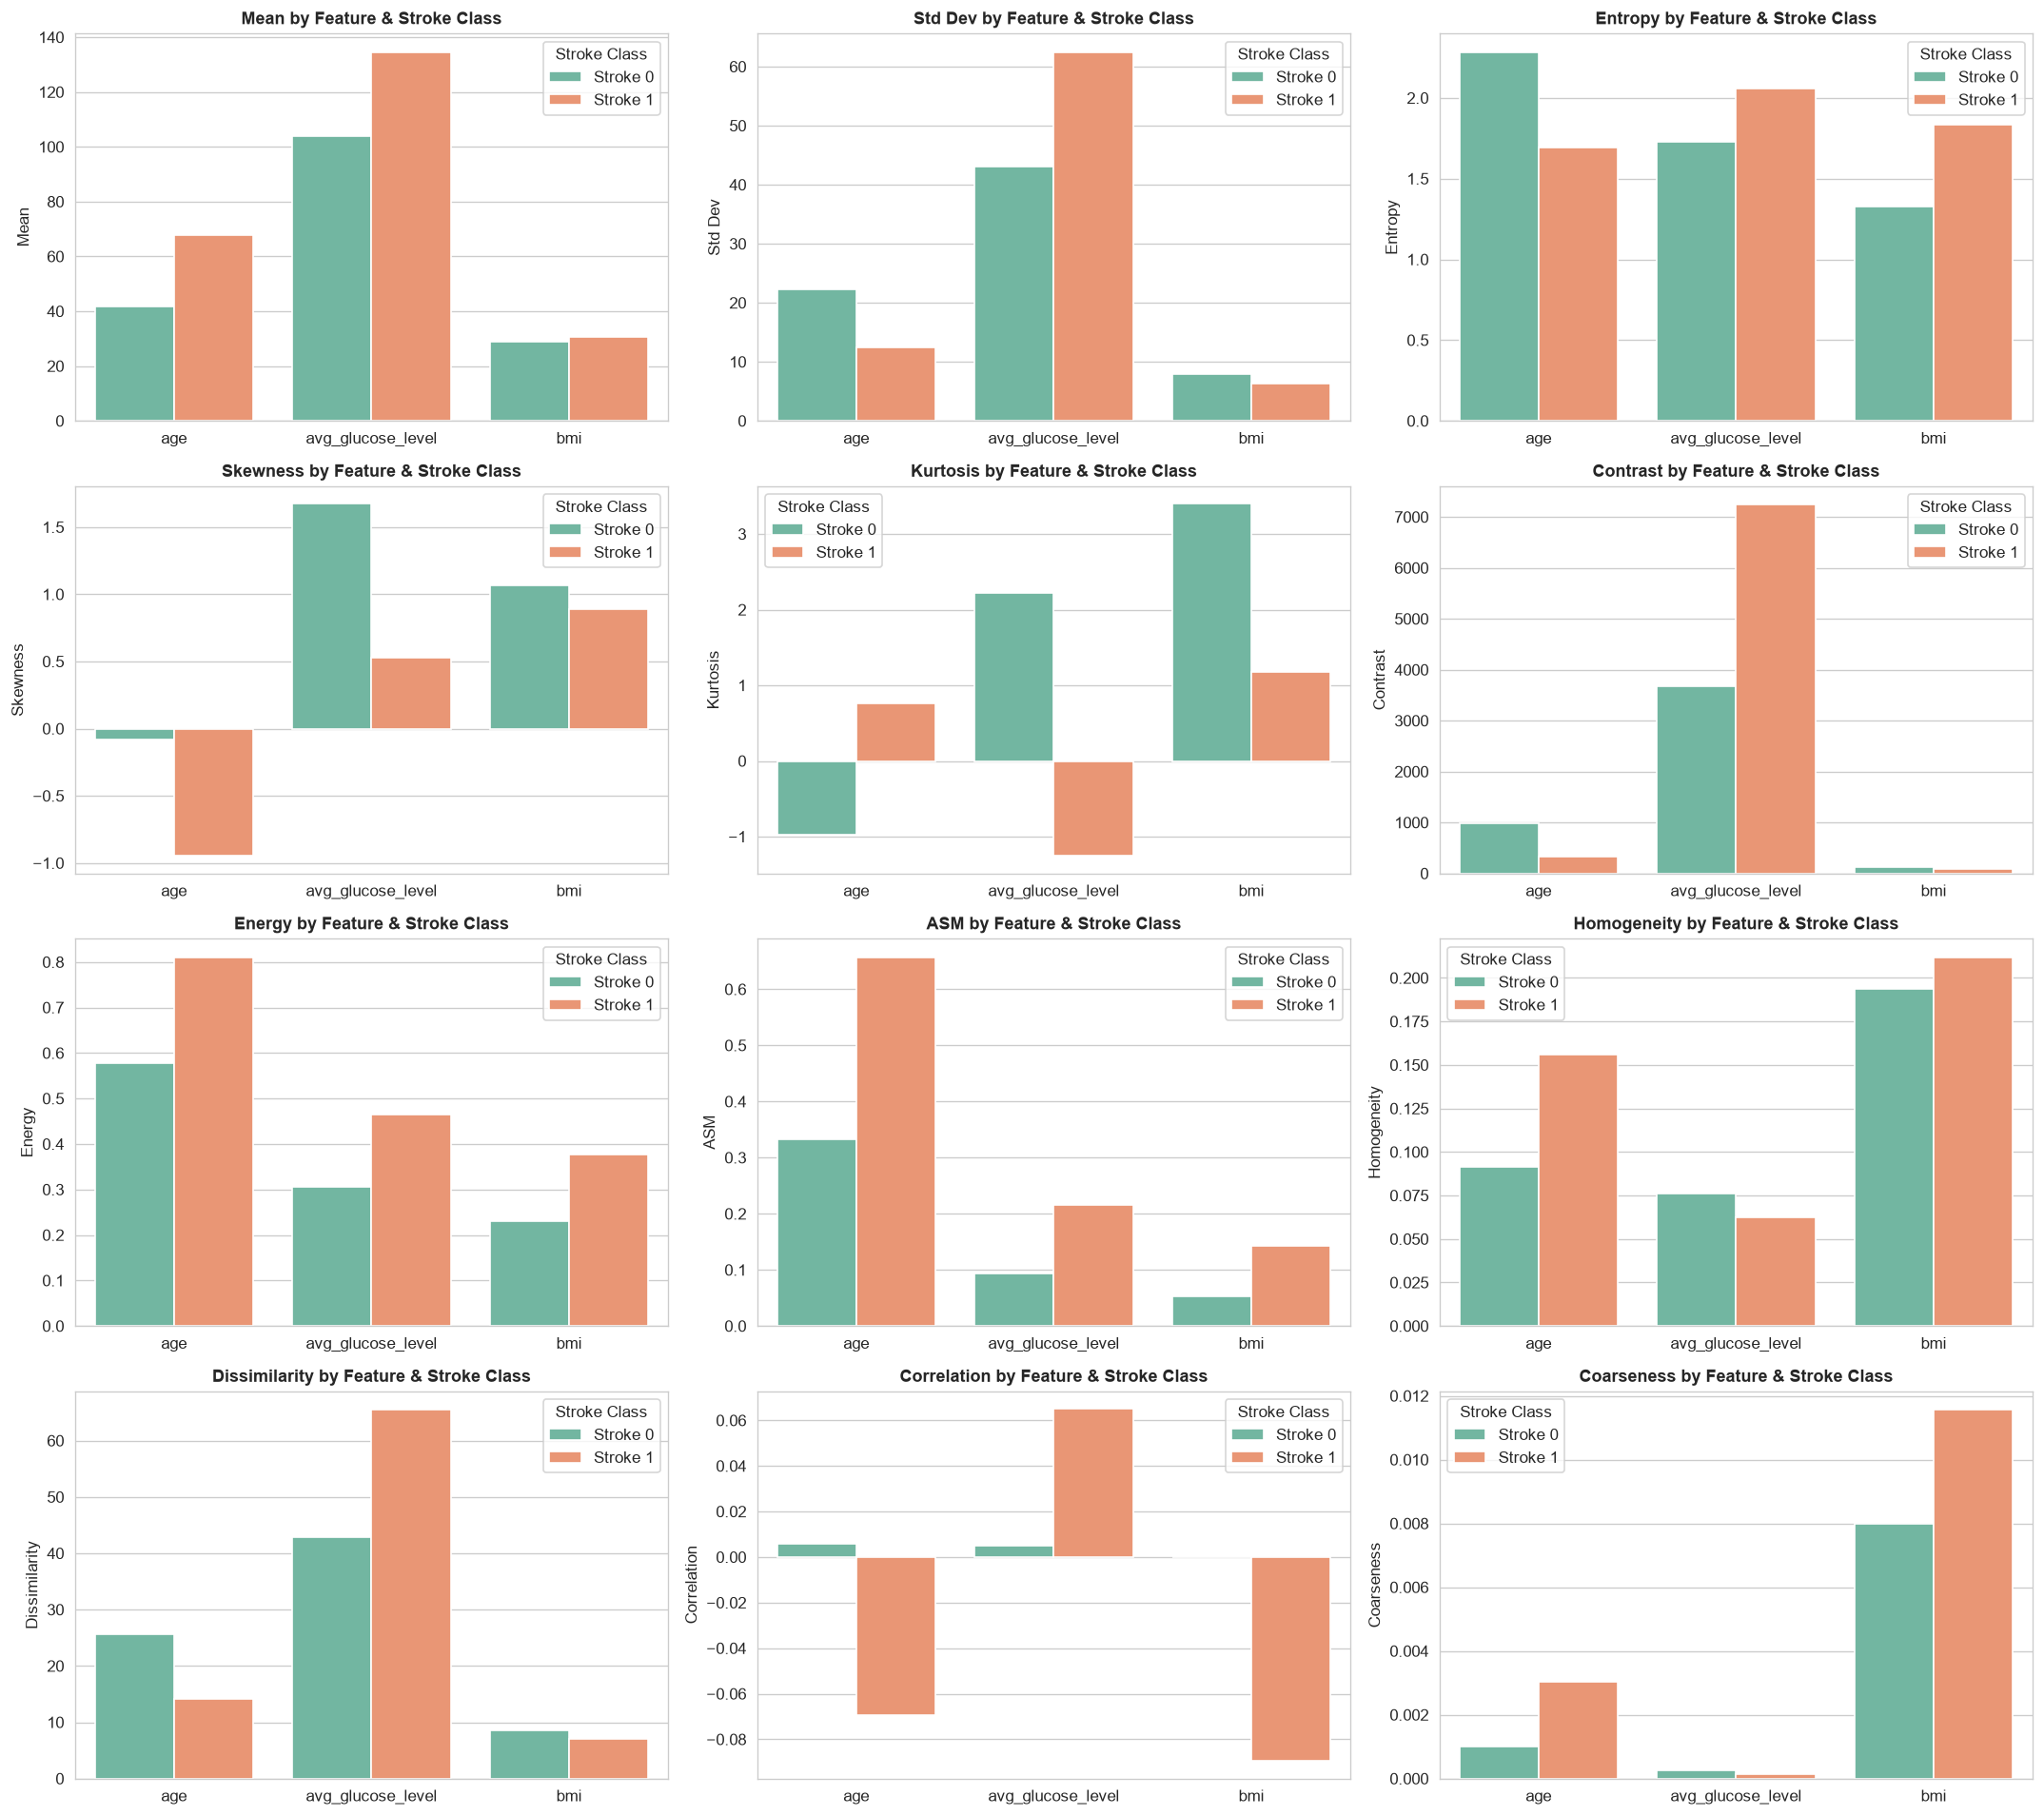

In [5]:
# 1. Violin Plots (Distribution + Density by Stroke Class)
num_cols = ['age', 'avg_glucose_level', 'bmi']

plt.figure(figsize=(15, 4))
for i, col in enumerate(num_cols, 1):
    plt.subplot(1, 3, i)
    sns.violinplot(x='stroke', y=col, data=data, palette='Set3', inner='quartile')
    plt.title(f'{col} Distribution by Stroke Class')
plt.tight_layout()
plt.show()

# 2. Function to Compute All Metrics
def compute_metrics(df, features, label='stroke'):
    records = []
    for stroke_val, group in df.groupby(label):
        for col in features:
            vals = group[col].dropna().values
            if len(vals) == 0:
                continue
            
            m, std, sk, kt = np.mean(vals), np.std(vals, ddof=1), skew(vals), kurtosis(vals)
            hist, _ = np.histogram(vals, bins=10, density=True)
            ent = entropy(hist[hist > 0])
            
            diffs = np.diff(vals) if len(vals) > 1 else np.array([0])
            contrast = np.mean(diffs**2)
            dissimilarity = np.mean(np.abs(diffs))
            
            vals_norm = (vals - vals.min()) / (vals.max() - vals.min() + 1e-8)
            asm = np.sum(vals_norm**2) / len(vals_norm)
            energy = np.sqrt(asm)
            
            homogeneity = np.mean(1.0 / (1.0 + np.abs(diffs)))
            corr = pd.Series(vals).autocorr(lag=1) if len(vals) > 1 else 0.0
            corr = 0.0 if np.isnan(corr) else corr
            coarseness = 1.0 / (contrast + 1e-8)

            records.append({
                'Stroke Class': f'Stroke {stroke_val}', 'Feature': col,
                'Mean': m, 'Std Dev': std, 'Entropy': ent, 'Skewness': sk, 'Kurtosis': kt,
                'Contrast': contrast, 'Energy': energy, 'ASM': asm,
                'Homogeneity': homogeneity, 'Dissimilarity': dissimilarity,
                'Correlation': corr, 'Coarseness': coarseness
            })
    return pd.DataFrame(records)

# 3. Calculate Metrics Dataframe
metrics_df = compute_metrics(data, num_cols)

# 4. Visualizations for Each Statistical & Texture Metric
metrics_list = [
    'Mean', 'Std Dev', 'Entropy', 'Skewness', 'Kurtosis', 'Contrast',
    'Energy', 'ASM', 'Homogeneity', 'Dissimilarity', 'Correlation', 'Coarseness'
]

fig, axes = plt.subplots(4, 3, figsize=(18, 16))
axes = axes.flatten()

for idx, metric in enumerate(metrics_list):
    sns.barplot(
        data=metrics_df, 
        x='Feature', 
        y=metric, 
        hue='Stroke Class', 
        palette='Set2', 
        ax=axes[idx]
    )
    axes[idx].set_title(f'{metric} by Feature & Stroke Class', fontsize=11, fontweight='bold')
    axes[idx].set_xlabel('')
    axes[idx].set_ylabel(metric)

plt.tight_layout()
plt.show()

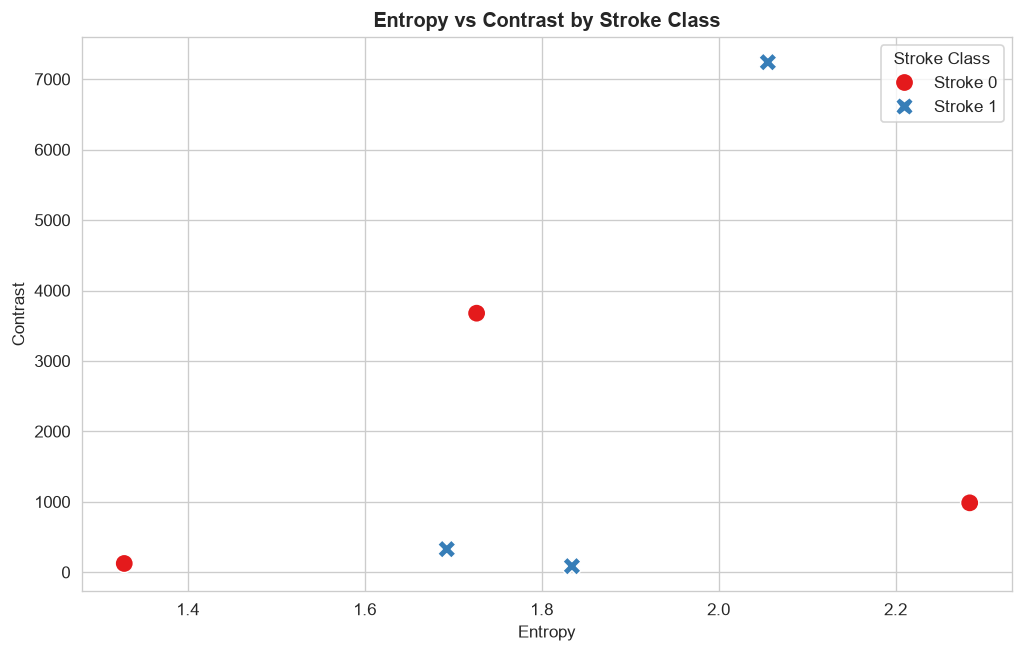

In [6]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=metrics_df, 
    x='Entropy', 
    y='Contrast', 
    hue='Stroke Class', 
    style='Stroke Class', 
    s=120, 
    palette='Set1'
)
plt.title('Entropy vs Contrast by Stroke Class', fontsize=12, fontweight='bold')
plt.show()

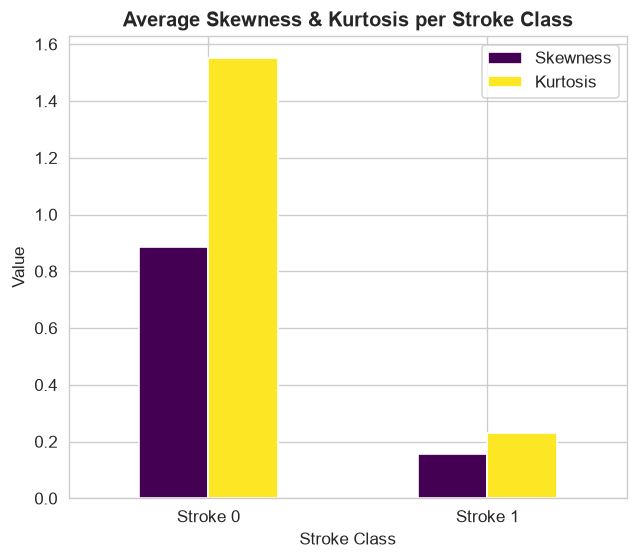

In [7]:
# Average Skewness & Kurtosis per Stroke Class
skew_kurt = metrics_df.groupby('Stroke Class')[['Skewness', 'Kurtosis']].mean()

skew_kurt.plot(kind='bar', figsize=(6, 5), rot=0, colormap='viridis')
plt.title('Average Skewness & Kurtosis per Stroke Class', fontsize=12, fontweight='bold')
plt.ylabel('Value')
plt.show()

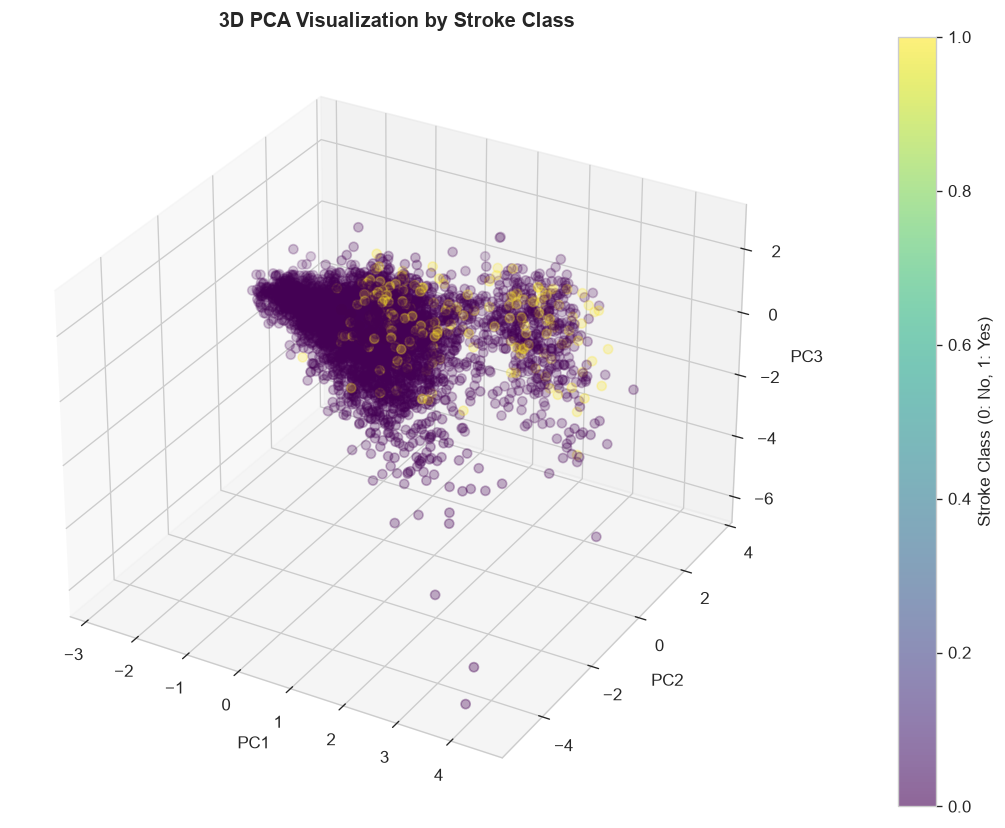

In [8]:
from mpl_toolkits.mplot3d import Axes3D
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Select continuous numerical features
num_cols = ['age', 'avg_glucose_level', 'bmi']
X = data[num_cols]

# Scale features to zero mean and unit variance
X_scaled = StandardScaler().fit_transform(X)

# PCA (3 components)
pca = PCA(n_components=3)
components = pca.fit_transform(X_scaled)

# 3D Visualization
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

scatter = ax.scatter(
    components[:, 0],
    components[:, 1],
    components[:, 2],
    c=data["stroke"],
    cmap="viridis",
    alpha=0.6,
    s=30
)

ax.set_title("3D PCA Visualization by Stroke Class", fontsize=12, fontweight='bold')
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_zlabel("PC3")

cbar = plt.colorbar(scatter, ax=ax, pad=0.1)
cbar.set_label('Stroke Class (0: No, 1: Yes)')

plt.tight_layout()
plt.show()

C:\Users\HP\AppData\Local\Temp\ipykernel_14664\289037977.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=data[col], palette='Set2')
C:\Users\HP\AppData\Local\Temp\ipykernel_14664\289037977.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=data[col], palette='Set2')
C:\Users\HP\AppData\Local\Temp\ipykernel_14664\289037977.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=data[col], palette='Set2')


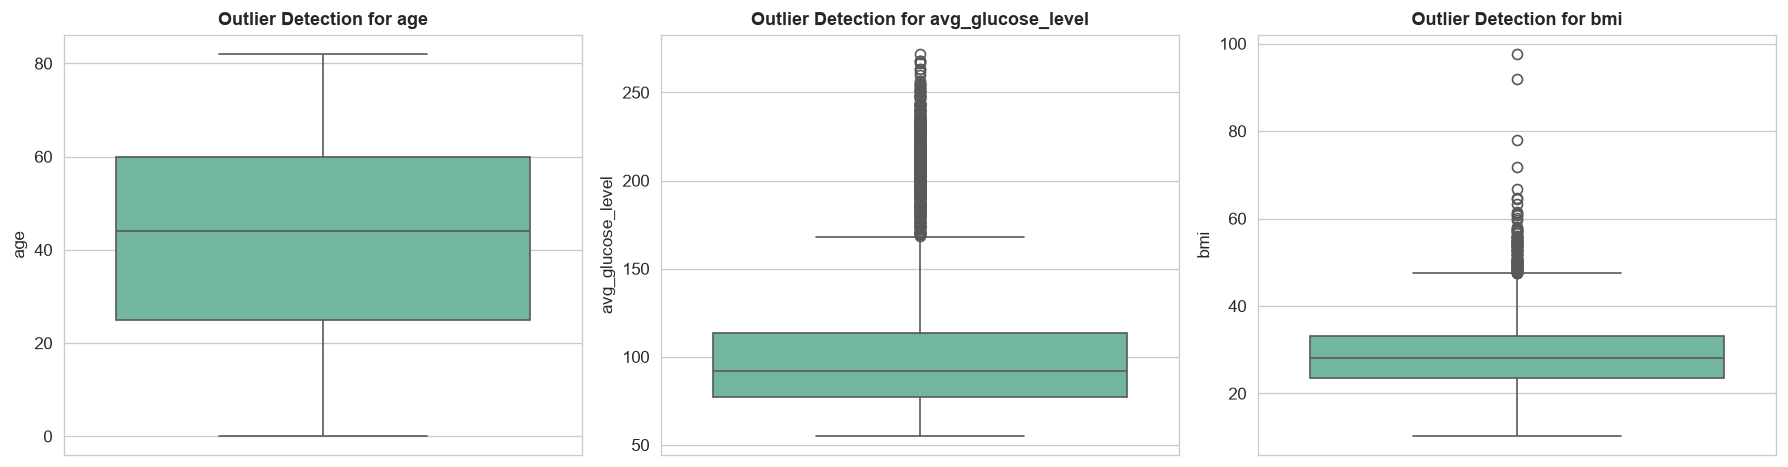

C:\Users\HP\AppData\Local\Temp\ipykernel_14664\289037977.py:46: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=data[col], palette='Set3')
C:\Users\HP\AppData\Local\Temp\ipykernel_14664\289037977.py:46: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=data[col], palette='Set3')
C:\Users\HP\AppData\Local\Temp\ipykernel_14664\289037977.py:46: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=data[col], palette='Set3')


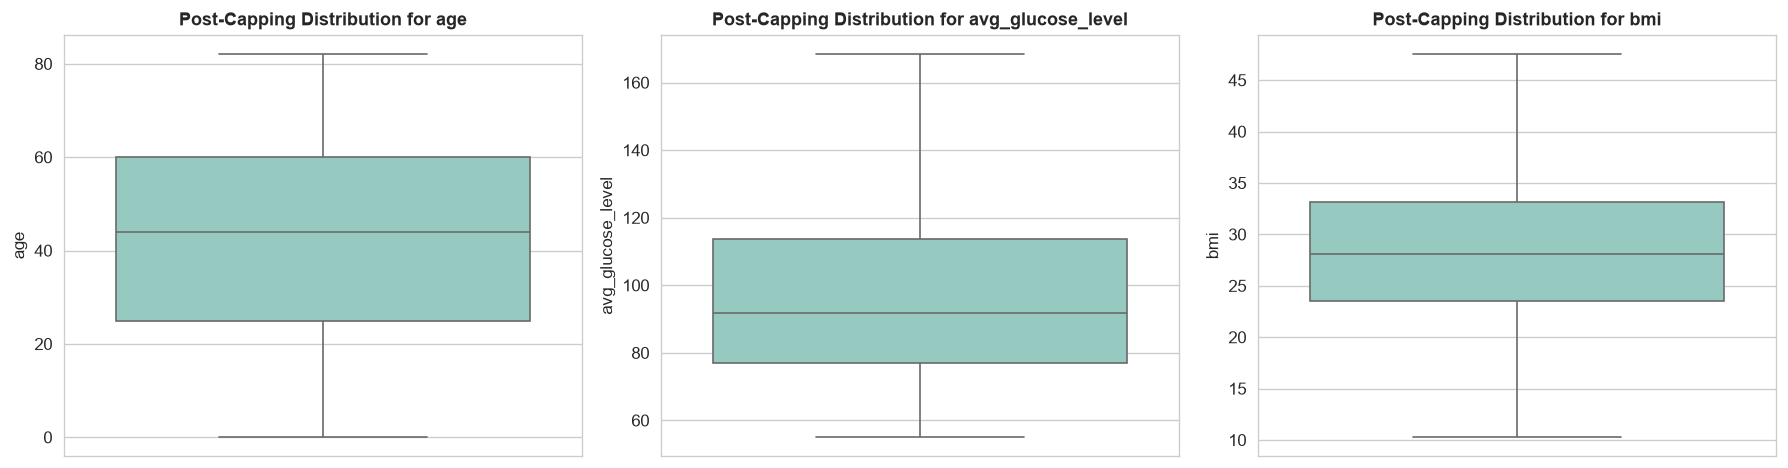

In [9]:
import math

# Ensure continuous numerical columns are defined
num_cols = ['age', 'avg_glucose_level', 'bmi']

# 1. Visualize Boxplots to inspect outliers before capping
n_cols = 3
n_rows = math.ceil(len(num_cols) / n_cols)

plt.figure(figsize=(5 * n_cols, 4 * n_rows))

for i, col in enumerate(num_cols, 1):
  plt.subplot(n_rows, n_cols, i)
  sns.boxplot(y=data[col], palette='Set2')
  plt.title(f'Outlier Detection for {col}', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()


# 2. Function to Cap Outliers using Interquartile Range (IQR) Method
def cap_outliers_iqr(df, cols):
  df_capped = df.copy()

  for col in cols:
    Q1 = df_capped[col].quantile(0.25)
    Q3 = df_capped[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    df_capped[col] = df_capped[col].clip(lower=lower_bound, upper=upper_bound)

  return df_capped


# Apply outlier capping to numerical features
data = cap_outliers_iqr(data, num_cols)

# 3. Re-visualize Boxplots post-capping to verify outlier handling
plt.figure(figsize=(5 * n_cols, 4 * n_rows))

for i, col in enumerate(num_cols, 1):
  plt.subplot(n_rows, n_cols, i)
  sns.boxplot(y=data[col], palette='Set3')
  plt.title(f'Post-Capping Distribution for {col}', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

Train shape: (3927, 16) Test shape: (982, 16)


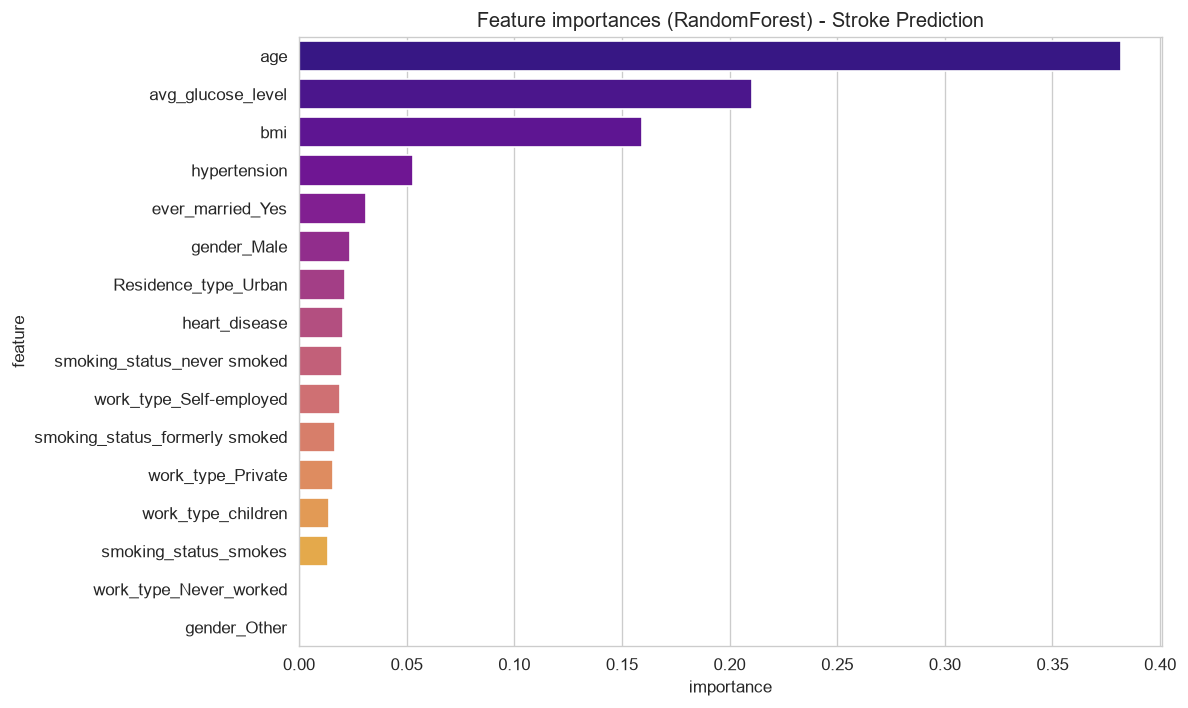

                           feature    importance
0                              age  3.817002e-01
3                avg_glucose_level  2.102337e-01
4                              bmi  1.591705e-01
1                     hypertension  5.281640e-02
7                 ever_married_Yes  3.108390e-02
5                      gender_Male  2.380070e-02
12            Residence_type_Urban  2.156636e-02
2                    heart_disease  2.065073e-02
14     smoking_status_never smoked  1.980823e-02
10         work_type_Self-employed  1.922631e-02
13  smoking_status_formerly smoked  1.666129e-02
9                work_type_Private  1.598809e-02
11              work_type_children  1.372266e-02
15           smoking_status_smokes  1.349722e-02
8           work_type_Never_worked  7.362880e-05
6                     gender_Other  6.759729e-08


In [10]:
# Random Forest
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier

RND = 42

# Load data
data = pd.read_csv('healthcare_dataset_stroke.csv')

# 'id' is just an identifier, so drop it (it would add noise to the model)
data = data.drop(columns=['id'])

# Encode categorical columns (gender, ever_married, work_type,
# Residence_type, smoking_status) as 0/1 dummy columns
data = pd.get_dummies(data, drop_first=True, dtype=int)

# Prepare features and labels
features = data.drop(columns=['stroke'])
labels = data['stroke']

# Split data into test and training sets
X_train, X_test, y_train, y_test = train_test_split(
    features, labels, test_size=0.20, random_state=RND, stratify=labels
)
print("Train shape:", X_train.shape, "Test shape:", X_test.shape)

# Standardize features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Baseline feature importance using RandomForest
# class_weight='balanced' helps with the heavy class imbalance (~4% stroke cases)
rf0 = RandomForestClassifier(random_state=RND, n_jobs=-1, class_weight='balanced')
rf0.fit(X_train_scaled, y_train)
importances = rf0.feature_importances_
feat_imp_df = pd.DataFrame({'feature': features.columns, 'importance': importances})
feat_imp_df = feat_imp_df.sort_values('importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='importance', y='feature', data=feat_imp_df,
            hue='feature', palette='plasma', legend=False)
plt.title('Feature importances (RandomForest) - Stroke Prediction')
plt.tight_layout()
plt.show()
print(feat_imp_df)

Train shape: (3927, 16) Test shape: (982, 16)
Stroke rate  train: 4.25% | test: 4.28%


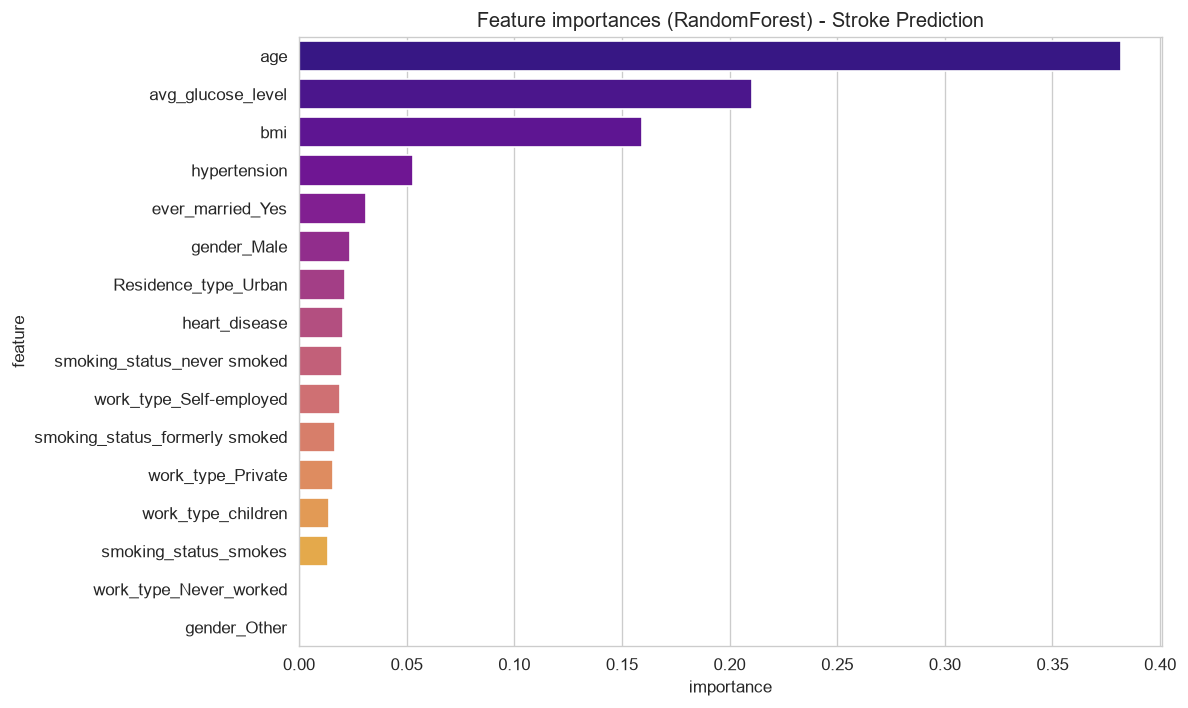

                           feature    importance
0                              age  3.817002e-01
3                avg_glucose_level  2.102337e-01
4                              bmi  1.591705e-01
1                     hypertension  5.281640e-02
7                 ever_married_Yes  3.108390e-02
5                      gender_Male  2.380070e-02
12            Residence_type_Urban  2.156636e-02
2                    heart_disease  2.065073e-02
14     smoking_status_never smoked  1.980823e-02
10         work_type_Self-employed  1.922631e-02
13  smoking_status_formerly smoked  1.666129e-02
9                work_type_Private  1.598809e-02
11              work_type_children  1.372266e-02
15           smoking_status_smokes  1.349722e-02
8           work_type_Never_worked  7.362880e-05
6                     gender_Other  6.759729e-08

Training 27 models on class-weighted data...

LogisticRegression           Acc 0.757 | Prec 0.114 | Rec 0.690 | F1 0.195 | ROC-AUC 0.810 | PR-AUC 0.191 | 0.0s
Logisti

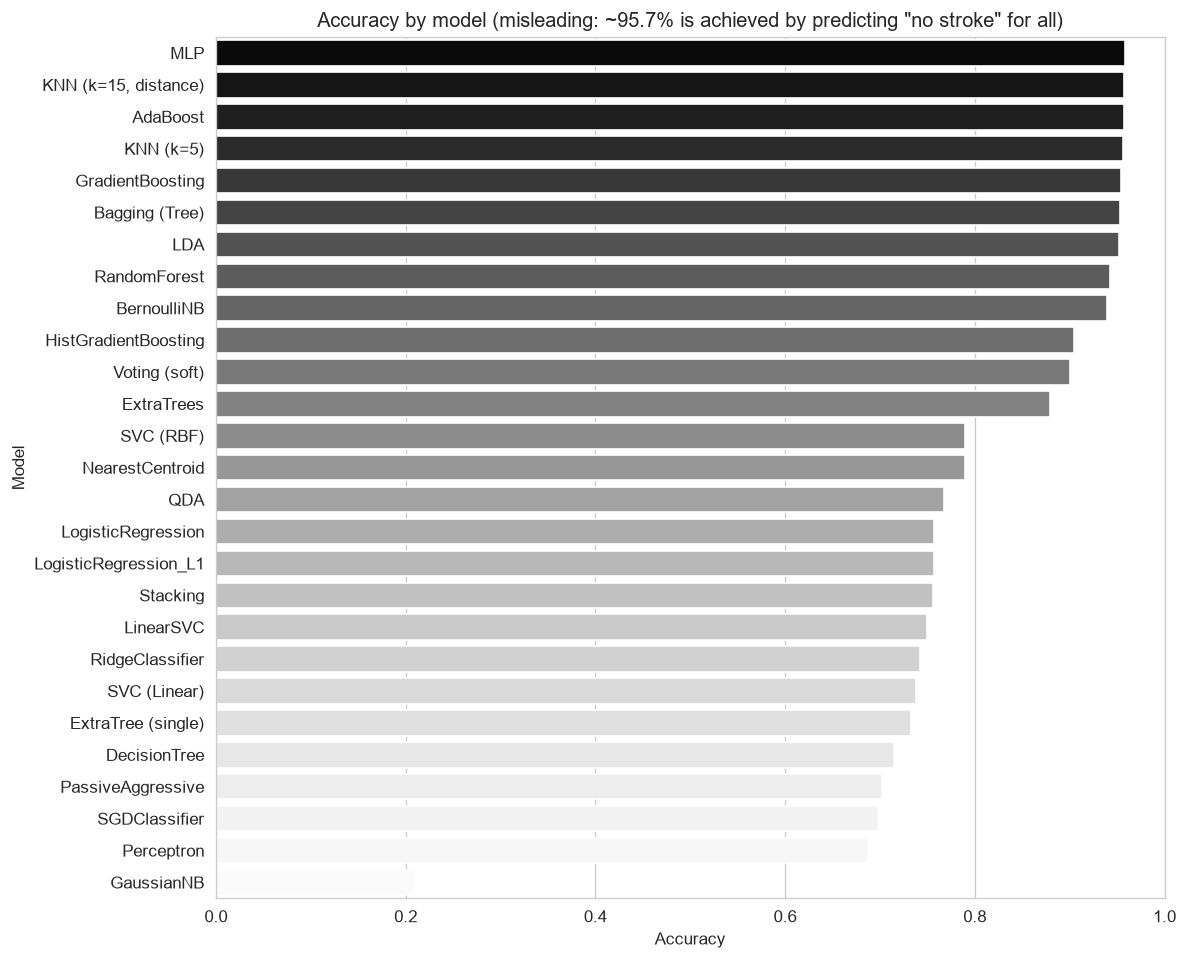

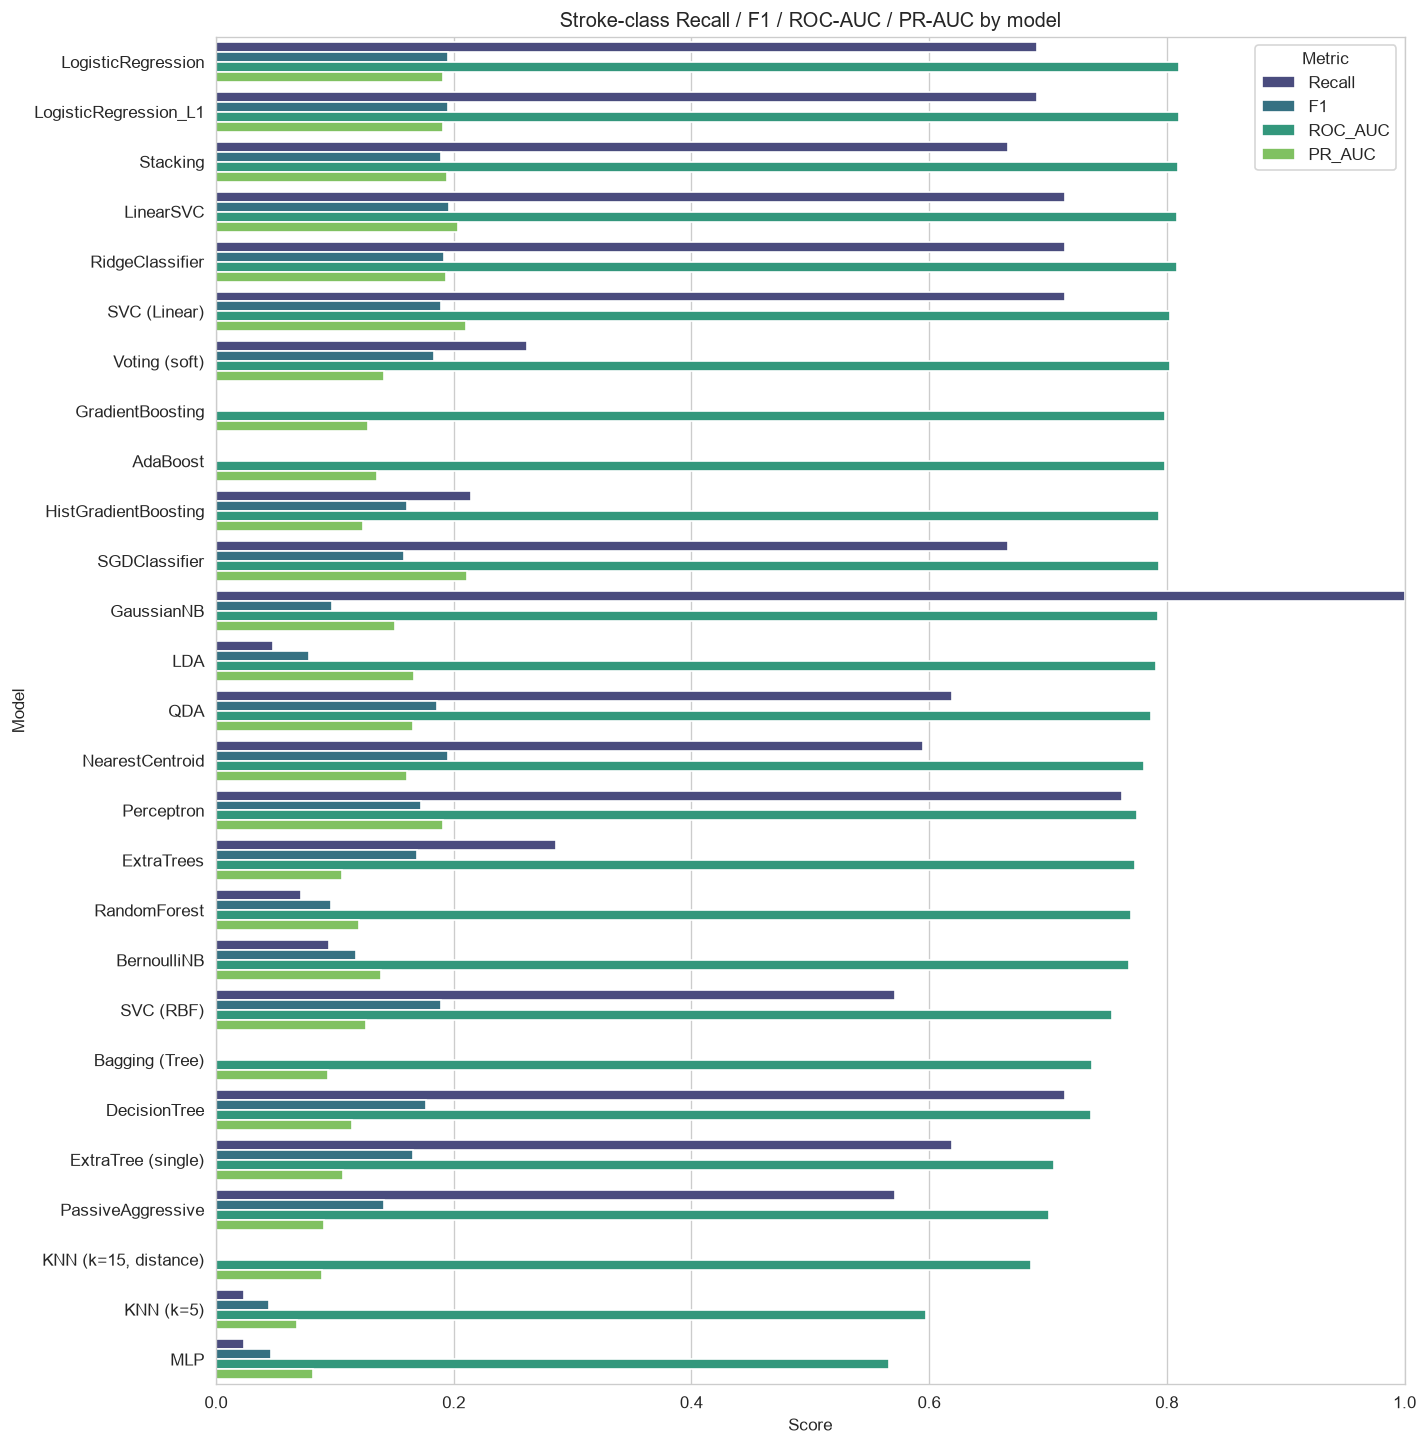

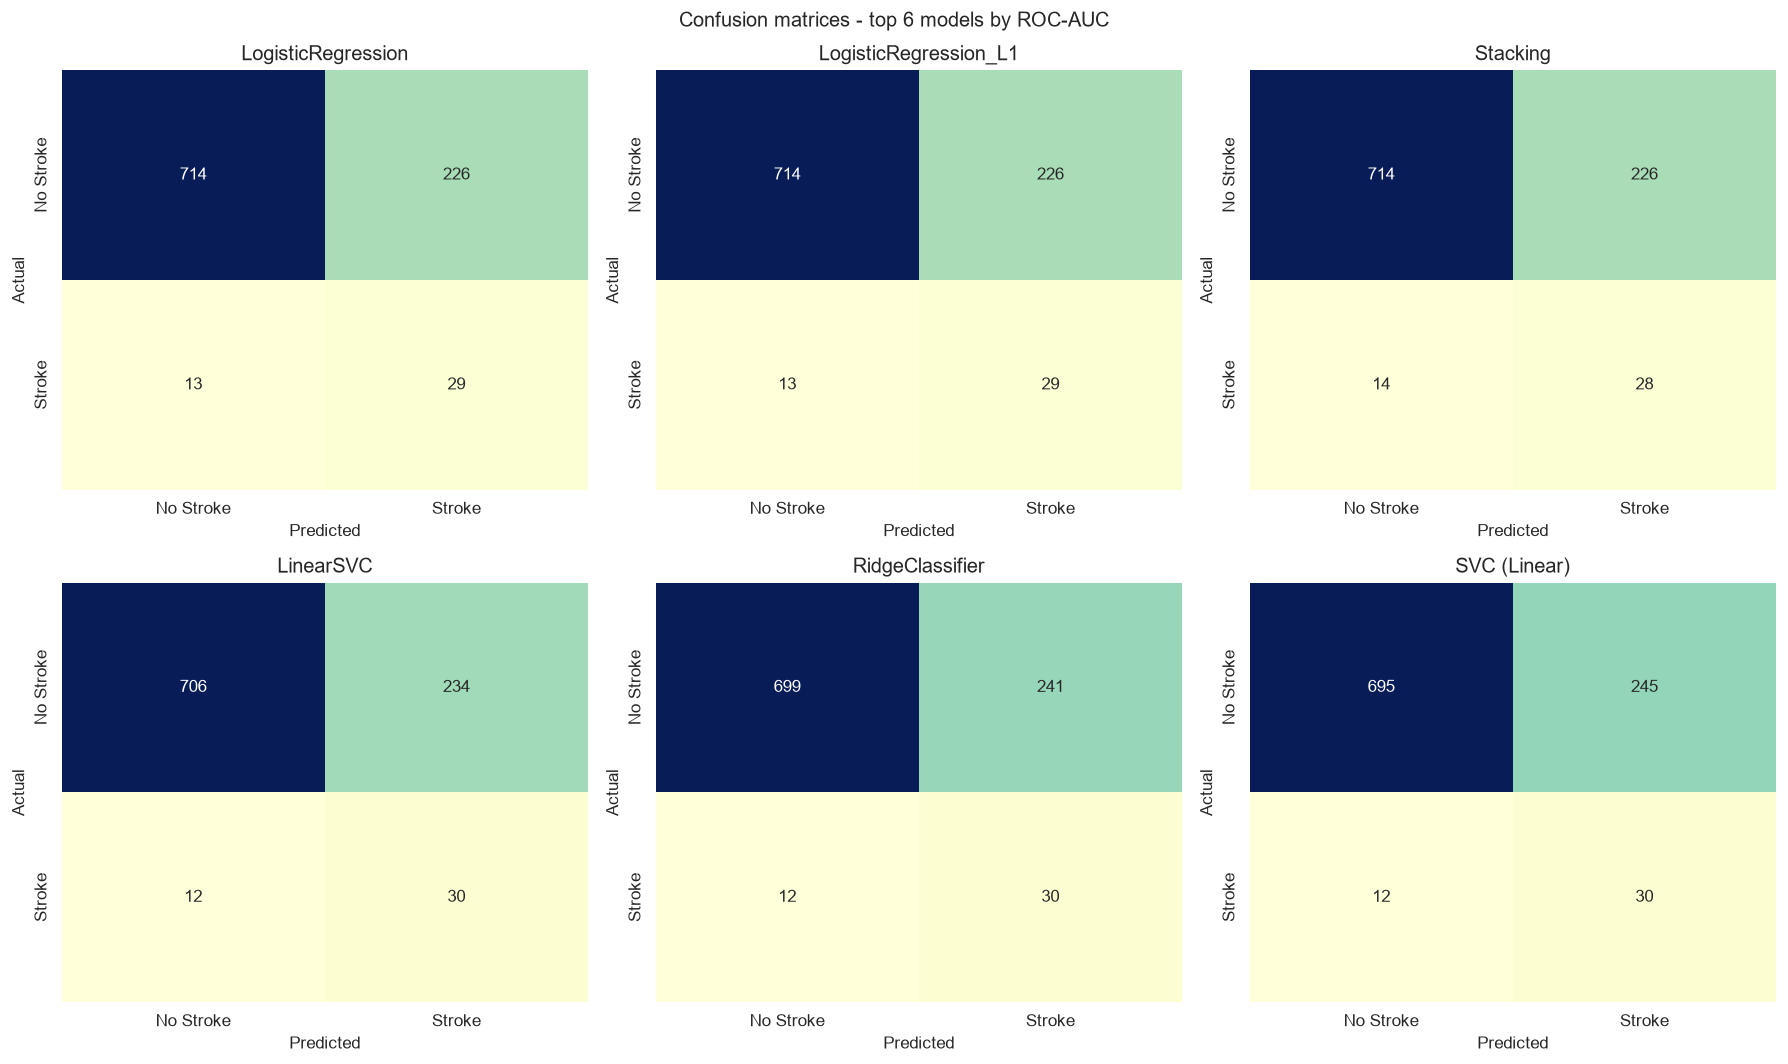


Best model by ROC-AUC : LogisticRegression
Best model by F1      : LinearSVC
Highest stroke recall : GaussianNB

Detailed report for LogisticRegression:
              precision    recall  f1-score   support

           0     0.9821    0.7596    0.8566       940
           1     0.1137    0.6905    0.1953        42

    accuracy                         0.7566       982
   macro avg     0.5479    0.7250    0.5260       982
weighted avg     0.9450    0.7566    0.8283       982



In [12]:
"""
Stroke Prediction Analysis - All-in-one script
------------------------------------------------
1. Load & prepare data
2. Baseline feature importance (RandomForest)
3. Train & evaluate many ML models (with class-imbalance handling)
4. Compare models (table + charts), confusion matrices for the top models

Optional libraries (the script skips them automatically if not installed):
    pip install xgboost lightgbm catboost imbalanced-learn
"""
import time
import warnings

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, balanced_accuracy_score,
                             matthews_corrcoef)

# ---- Models ----
from sklearn.linear_model import (LogisticRegression, RidgeClassifier, SGDClassifier,
                                  Perceptron, PassiveAggressiveClassifier)
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.naive_bayes import GaussianNB, BernoulliNB
from sklearn.neighbors import KNeighborsClassifier, NearestCentroid
from sklearn.svm import SVC, LinearSVC
from sklearn.tree import DecisionTreeClassifier, ExtraTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier,
                              GradientBoostingClassifier, HistGradientBoostingClassifier,
                              AdaBoostClassifier, BaggingClassifier,
                              VotingClassifier, StackingClassifier)
from sklearn.neural_network import MLPClassifier

warnings.filterwarnings('ignore')

RND = 42
DATA_PATH = 'healthcare_dataset_stroke.csv'

# Optional boosting libraries
try:
    from xgboost import XGBClassifier
except ImportError:
    XGBClassifier = None
try:
    from lightgbm import LGBMClassifier
except ImportError:
    LGBMClassifier = None
try:
    from catboost import CatBoostClassifier
except ImportError:
    CatBoostClassifier = None
try:
    from imblearn.over_sampling import SMOTE
    from imblearn.ensemble import BalancedRandomForestClassifier
except ImportError:
    SMOTE = None
    BalancedRandomForestClassifier = None

# ======================================================================
# 1. LOAD & PREPARE DATA
# ======================================================================
data = pd.read_csv(DATA_PATH)
data = data.drop(columns=['id'])                       # identifier only, not a feature
data = pd.get_dummies(data, drop_first=True, dtype=int)  # encode categorical columns

features = data.drop(columns=['stroke'])
labels = data['stroke']

X_train, X_test, y_train, y_test = train_test_split(
    features, labels, test_size=0.20, random_state=RND, stratify=labels
)
print("Train shape:", X_train.shape, "Test shape:", X_test.shape)
print("Stroke rate  train: {:.2%} | test: {:.2%}".format(y_train.mean(), y_test.mean()))

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Ratio used by boosting libraries to up-weight the rare stroke class
neg, pos = (y_train == 0).sum(), (y_train == 1).sum()
SPW = neg / pos

# ======================================================================
# 2. BASELINE FEATURE IMPORTANCE
# ======================================================================
rf0 = RandomForestClassifier(random_state=RND, n_jobs=-1, class_weight='balanced')
rf0.fit(X_train_scaled, y_train)
feat_imp_df = (pd.DataFrame({'feature': features.columns, 'importance': rf0.feature_importances_})
               .sort_values('importance', ascending=False))

plt.figure(figsize=(10, 6))
sns.barplot(x='importance', y='feature', data=feat_imp_df, hue='feature',
            palette='plasma', legend=False)
plt.title('Feature importances (RandomForest) - Stroke Prediction')
plt.tight_layout()
plt.show()
print(feat_imp_df)

# ======================================================================
# 3. EVALUATION UTILITY
# ======================================================================
def get_scores(model, X):
    """Continuous score used for ROC-AUC / PR-AUC (works for any model type)."""
    if hasattr(model, 'predict_proba'):
        return model.predict_proba(X)[:, 1]
    if hasattr(model, 'decision_function'):
        return model.decision_function(X)
    return model.predict(X)  # fallback (e.g. NearestCentroid)


def evaluate_model(model, Xtr, Xte, ytr, yte, name='model', verbose=True):
    t0 = time.time()
    model.fit(Xtr, ytr)
    train_time = time.time() - t0

    preds = model.predict(Xte)
    scores = get_scores(model, Xte)

    res = {
        'accuracy': accuracy_score(yte, preds),
        'balanced_acc': balanced_accuracy_score(yte, preds),
        'precision': precision_score(yte, preds, zero_division=0),
        'recall': recall_score(yte, preds),
        'f1': f1_score(yte, preds),
        'mcc': matthews_corrcoef(yte, preds),
        'roc_auc': roc_auc_score(yte, scores),
        'pr_auc': average_precision_score(yte, scores),
        'time_s': train_time,
        'confusion_matrix': confusion_matrix(yte, preds),
        'report': classification_report(yte, preds, digits=4, zero_division=0),
        'model': model,
    }
    if verbose:
        print(f"{name:<28} Acc {res['accuracy']:.3f} | Prec {res['precision']:.3f} | "
              f"Rec {res['recall']:.3f} | F1 {res['f1']:.3f} | "
              f"ROC-AUC {res['roc_auc']:.3f} | PR-AUC {res['pr_auc']:.3f} | {train_time:.1f}s")
    return res


# ======================================================================
# 4. MODEL ZOO
#    class_weight='balanced' is used wherever the model supports it.
# ======================================================================
models_dict = {
    # --- Linear models ---
    'LogisticRegression': LogisticRegression(random_state=RND, max_iter=2000, class_weight='balanced'),
    'LogisticRegression_L1': LogisticRegression(penalty='l1', solver='liblinear', random_state=RND,
                                                class_weight='balanced'),
    'RidgeClassifier': RidgeClassifier(class_weight='balanced', random_state=RND),
    'SGDClassifier': SGDClassifier(loss='log_loss', class_weight='balanced', random_state=RND),
    'Perceptron': Perceptron(class_weight='balanced', random_state=RND),
    'PassiveAggressive': PassiveAggressiveClassifier(class_weight='balanced', random_state=RND),

    # --- Discriminant analysis / Naive Bayes ---
    'LDA': LinearDiscriminantAnalysis(),
    'QDA': QuadraticDiscriminantAnalysis(reg_param=0.1),
    'GaussianNB': GaussianNB(),
    'BernoulliNB': BernoulliNB(),

    # --- Distance based ---
    'KNN (k=5)': KNeighborsClassifier(n_neighbors=5),
    'KNN (k=15, distance)': KNeighborsClassifier(n_neighbors=15, weights='distance'),
    'NearestCentroid': NearestCentroid(),

    # --- SVMs ---
    'SVC (RBF)': SVC(kernel='rbf', class_weight='balanced', random_state=RND),
    'SVC (Linear)': SVC(kernel='linear', class_weight='balanced', random_state=RND),
    'LinearSVC': LinearSVC(class_weight='balanced', random_state=RND, max_iter=5000),

    # --- Trees ---
    'DecisionTree': DecisionTreeClassifier(max_depth=6, class_weight='balanced', random_state=RND),
    'ExtraTree (single)': ExtraTreeClassifier(max_depth=6, class_weight='balanced', random_state=RND),

    # --- Ensembles ---
    'RandomForest': RandomForestClassifier(n_estimators=300, class_weight='balanced_subsample',
                                           min_samples_leaf=3, random_state=RND, n_jobs=-1),
    'ExtraTrees': ExtraTreesClassifier(n_estimators=300, class_weight='balanced_subsample',
                                       min_samples_leaf=3, random_state=RND, n_jobs=-1),
    'GradientBoosting': GradientBoostingClassifier(random_state=RND),
    'HistGradientBoosting': HistGradientBoostingClassifier(class_weight='balanced', random_state=RND),
    'AdaBoost': AdaBoostClassifier(n_estimators=200, random_state=RND),
    'Bagging (Tree)': BaggingClassifier(n_estimators=100, random_state=RND, n_jobs=-1),

    # --- Neural network ---
    'MLP': MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=500, early_stopping=True,
                         random_state=RND),
}

# Optional boosting libraries
if XGBClassifier is not None:
    models_dict['XGBoost'] = XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4,
                                           scale_pos_weight=SPW, eval_metric='logloss',
                                           random_state=RND, n_jobs=-1)
if LGBMClassifier is not None:
    models_dict['LightGBM'] = LGBMClassifier(n_estimators=300, learning_rate=0.05, max_depth=4,
                                             class_weight='balanced', random_state=RND,
                                             n_jobs=-1, verbose=-1)
if CatBoostClassifier is not None:
    models_dict['CatBoost'] = CatBoostClassifier(iterations=300, learning_rate=0.05, depth=4,
                                                 auto_class_weights='Balanced', random_seed=RND,
                                                 verbose=0, allow_writing_files=False)
if BalancedRandomForestClassifier is not None:
    models_dict['BalancedRandomForest'] = BalancedRandomForestClassifier(
        n_estimators=300, random_state=RND, n_jobs=-1)

# --- Combined models (Voting / Stacking of a few strong, diverse learners) ---
_base = [
    ('lr', LogisticRegression(max_iter=2000, class_weight='balanced', random_state=RND)),
    ('rf', RandomForestClassifier(n_estimators=200, class_weight='balanced_subsample',
                                  min_samples_leaf=3, random_state=RND, n_jobs=-1)),
    ('hgb', HistGradientBoostingClassifier(class_weight='balanced', random_state=RND)),
]
models_dict['Voting (soft)'] = VotingClassifier(estimators=_base, voting='soft')
models_dict['Stacking'] = StackingClassifier(
    estimators=_base,
    final_estimator=LogisticRegression(class_weight='balanced', max_iter=2000),
    cv=5, n_jobs=-1)

# ======================================================================
# 5. TRAIN & EVALUATE ALL MODELS
# ======================================================================
print(f"\nTraining {len(models_dict)} models on class-weighted data...\n")
results = {}
for name, mdl in models_dict.items():
    try:
        results[name] = evaluate_model(mdl, X_train_scaled, X_test_scaled,
                                       y_train, y_test, name=name)
    except Exception as e:
        print(f"{name:<28} FAILED: {e}")

# ---- Optional: SMOTE variants (oversampling applied to TRAINING data only) ----
if SMOTE is not None:
    print("\nTraining SMOTE variants...\n")
    X_sm, y_sm = SMOTE(random_state=RND).fit_resample(X_train_scaled, y_train)
    smote_models = {
        'SMOTE + LogisticRegression': LogisticRegression(max_iter=2000, random_state=RND),
        'SMOTE + RandomForest': RandomForestClassifier(n_estimators=300, random_state=RND, n_jobs=-1),
        'SMOTE + GradientBoosting': GradientBoostingClassifier(random_state=RND),
        'SMOTE + SVC (RBF)': SVC(random_state=RND),
        'SMOTE + KNN (k=5)': KNeighborsClassifier(n_neighbors=5),
    }
    for name, mdl in smote_models.items():
        results[name] = evaluate_model(mdl, X_sm, X_test_scaled, y_sm, y_test, name=name)

# ======================================================================
# 6. COMPARISON TABLE
# ======================================================================
metrics_df = pd.DataFrame({
    'Model': list(results.keys()),
    'Accuracy': [v['accuracy'] for v in results.values()],
    'Balanced_Acc': [v['balanced_acc'] for v in results.values()],
    'Precision': [v['precision'] for v in results.values()],
    'Recall': [v['recall'] for v in results.values()],
    'F1': [v['f1'] for v in results.values()],
    'MCC': [v['mcc'] for v in results.values()],
    'ROC_AUC': [v['roc_auc'] for v in results.values()],
    'PR_AUC': [v['pr_auc'] for v in results.values()],
    'Train_Time_s': [v['time_s'] for v in results.values()],
}).round(4).sort_values('ROC_AUC', ascending=False).reset_index(drop=True)

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', None)
print("\n================ MODEL COMPARISON (sorted by ROC-AUC) ================")
print(metrics_df.to_string(index=False))
metrics_df.to_csv('model_comparison_results.csv', index=False)
print("\nSaved: model_comparison_results.csv")

# ======================================================================
# 7. CROSS-VALIDATION of the top models (more reliable than a single split)
#    The test set has only ~42 stroke cases, so single-split scores are noisy.
# ======================================================================
top_names = metrics_df['Model'].head(5).tolist()
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RND)
cv_rows = []
for name in top_names:
    if name.startswith('SMOTE'):
        continue  # SMOTE needs an imblearn Pipeline for a leak-free CV; skipped here
    mdl = results[name]['model']
    auc_cv = cross_val_score(mdl, X_train_scaled, y_train, cv=cv, scoring='roc_auc', n_jobs=-1)
    f1_cv = cross_val_score(mdl, X_train_scaled, y_train, cv=cv, scoring='f1', n_jobs=-1)
    cv_rows.append({'Model': name,
                    'CV_ROC_AUC_mean': auc_cv.mean(), 'CV_ROC_AUC_std': auc_cv.std(),
                    'CV_F1_mean': f1_cv.mean(), 'CV_F1_std': f1_cv.std()})
cv_df = pd.DataFrame(cv_rows).round(4)
print("\n================ 5-FOLD CROSS-VALIDATION (top models) ================")
print(cv_df.to_string(index=False))

# ======================================================================
# 8. CHARTS
# ======================================================================
# 8a. Accuracy (kept for reference - misleading on imbalanced data)
acc_sorted = metrics_df.sort_values('Accuracy', ascending=False)
plt.figure(figsize=(10, max(6, 0.3 * len(acc_sorted))))
sns.barplot(data=acc_sorted, y='Model', x='Accuracy', hue='Model', palette='Greys_r', legend=False)
plt.xlim(0, 1)
plt.title('Accuracy by model (misleading: ~95.7% is achieved by predicting "no stroke" for all)')
plt.tight_layout()
plt.show()

# 8b. Metrics that matter for imbalanced data
melted = metrics_df.melt(id_vars='Model', value_vars=['Recall', 'F1', 'ROC_AUC', 'PR_AUC'],
                         var_name='Metric', value_name='Score')
plt.figure(figsize=(12, max(7, 0.45 * len(metrics_df))))
sns.barplot(data=melted, y='Model', x='Score', hue='Metric', palette='viridis',
            order=metrics_df['Model'])
plt.xlim(0, 1)
plt.title('Stroke-class Recall / F1 / ROC-AUC / PR-AUC by model')
plt.tight_layout()
plt.show()

# 8c. Confusion matrices of the top 6 models
top6 = metrics_df['Model'].head(6).tolist()
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, name in zip(axes.ravel(), top6):
    sns.heatmap(results[name]['confusion_matrix'], annot=True, fmt='d', cmap='YlGnBu',
                xticklabels=['No Stroke', 'Stroke'], yticklabels=['No Stroke', 'Stroke'],
                ax=ax, cbar=False)
    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
plt.suptitle('Confusion matrices - top 6 models by ROC-AUC')
plt.tight_layout()
plt.show()

# ======================================================================
# 9. BEST MODELS
# ======================================================================
best_auc = metrics_df.loc[metrics_df['ROC_AUC'].idxmax(), 'Model']
best_f1 = metrics_df.loc[metrics_df['F1'].idxmax(), 'Model']
best_recall = metrics_df.loc[metrics_df['Recall'].idxmax(), 'Model']
print(f"\nBest model by ROC-AUC : {best_auc}")
print(f"Best model by F1      : {best_f1}")
print(f"Highest stroke recall : {best_recall}")
print(f"\nDetailed report for {best_auc}:\n{results[best_auc]['report']}")

Train shape: (3927, 16) Test shape: (982, 16)

>>> Tuning RandomForest: 48 combinations x 5 folds

[RandomForest] best params: {'class_weight': 'balanced', 'max_depth': 10, 'min_samples_leaf': 5, 'min_samples_split': 2, 'n_estimators': 300}
[RandomForest] CV  ROC-AUC 0.8406 | PR-AUC 0.1715 | F1 0.2392 | Recall 0.6105  (41s)

>>> Tuning SVC: 18 combinations x 5 folds

[SVC] best params: {'C': 0.1, 'class_weight': 'balanced', 'gamma': 1, 'kernel': 'linear'}
[SVC] CV  ROC-AUC 0.8463 | PR-AUC 0.1895 | F1 0.2054 | Recall 0.7840  (12s)

>>> Tuning KNN: 16 combinations x 5 folds

[KNN] best params: {'metric': 'manhattan', 'n_neighbors': 31, 'weights': 'uniform'}
[KNN] CV  ROC-AUC 0.7713 | PR-AUC 0.1404 | F1 0.0000 | Recall 0.0000  (2s)

>>> Tuning GradientBoosting: 144 combinations x 5 folds

[GradientBoosting] best params: {'learning_rate': 0.01, 'max_depth': 3, 'min_samples_leaf': 5, 'min_samples_split': 2, 'n_estimators': 100, 'subsample': 0.8}
[GradientBoosting] CV  ROC-AUC 0.8522 | PR-AU

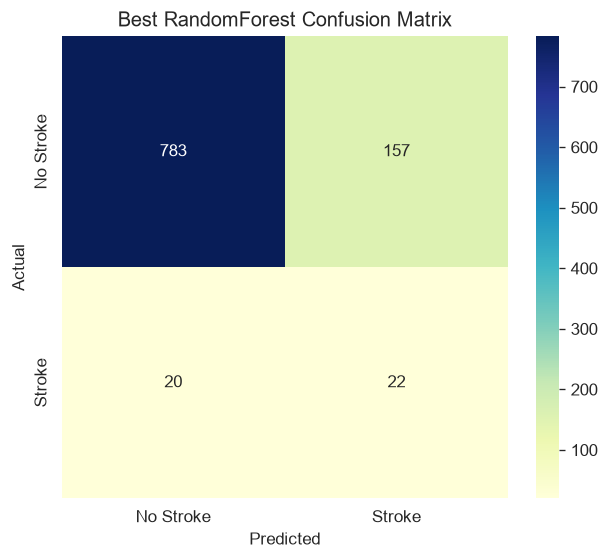


Best SVC Accuracy: 0.731161
Classification report for Best SVC:
              precision    recall  f1-score   support

           0     0.9829    0.7319    0.8390       940
           1     0.1064    0.7143    0.1852        42

    accuracy                         0.7312       982
   macro avg     0.5446    0.7231    0.5121       982
weighted avg     0.9454    0.7312    0.8111       982



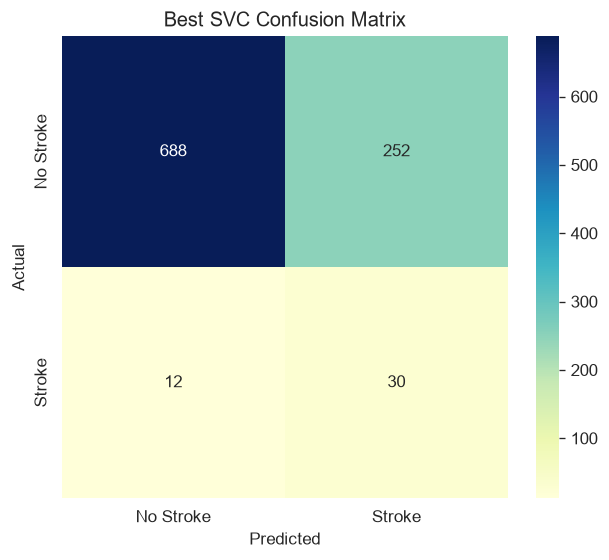


Best KNN Accuracy: 0.957230
Classification report for Best KNN:
              precision    recall  f1-score   support

           0     0.9572    1.0000    0.9781       940
           1     0.0000    0.0000    0.0000        42

    accuracy                         0.9572       982
   macro avg     0.4786    0.5000    0.4891       982
weighted avg     0.9163    0.9572    0.9363       982



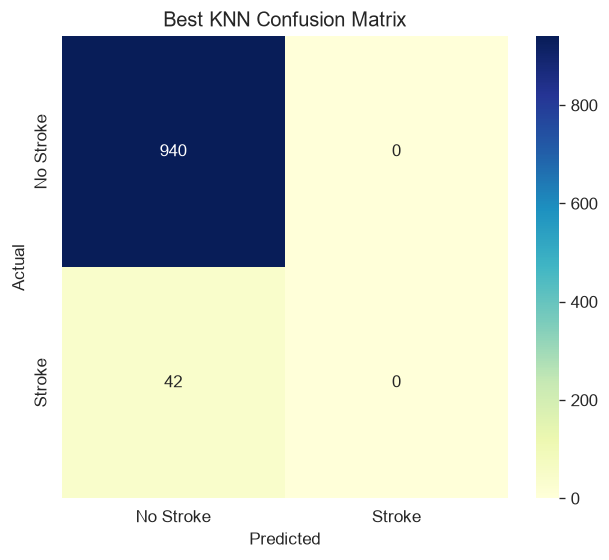


Best GradientBoosting Accuracy: 0.957230
Classification report for Best GradientBoosting:
              precision    recall  f1-score   support

           0     0.9572    1.0000    0.9781       940
           1     0.0000    0.0000    0.0000        42

    accuracy                         0.9572       982
   macro avg     0.4786    0.5000    0.4891       982
weighted avg     0.9163    0.9572    0.9363       982



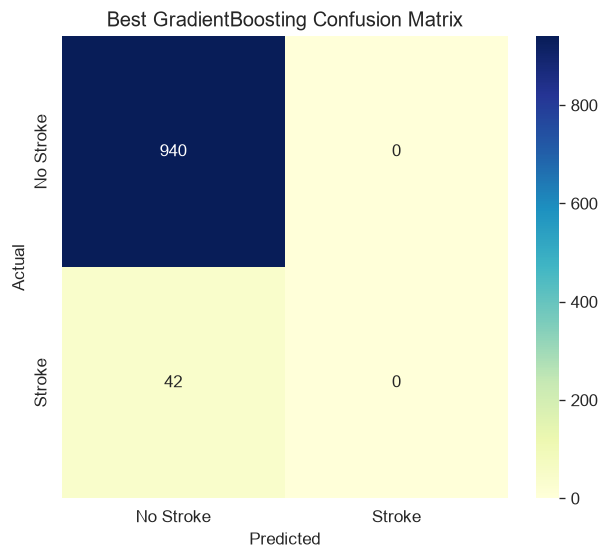


Best LogisticRegression Accuracy: 0.957230
Classification report for Best LogisticRegression:
              precision    recall  f1-score   support

           0     0.9572    1.0000    0.9781       940
           1     0.0000    0.0000    0.0000        42

    accuracy                         0.9572       982
   macro avg     0.4786    0.5000    0.4891       982
weighted avg     0.9163    0.9572    0.9363       982



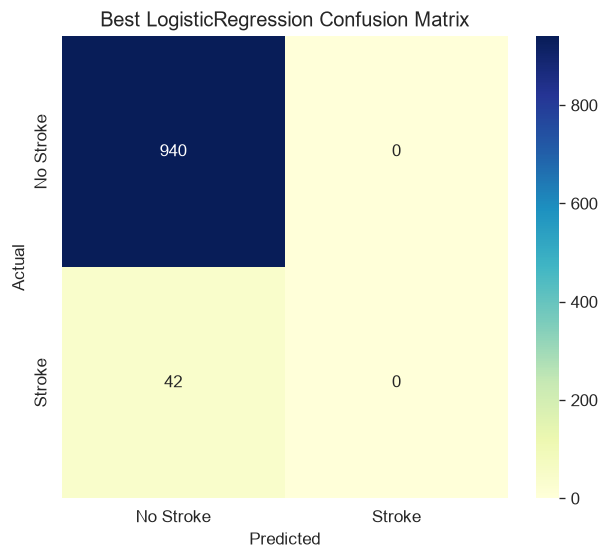


Best HistGradientBoosting Accuracy: 0.720978
Classification report for Best HistGradientBoosting:
              precision    recall  f1-score   support

           0     0.9840    0.7202    0.8317       940
           1     0.1054    0.7381    0.1845        42

    accuracy                         0.7210       982
   macro avg     0.5447    0.7292    0.5081       982
weighted avg     0.9464    0.7210    0.8040       982



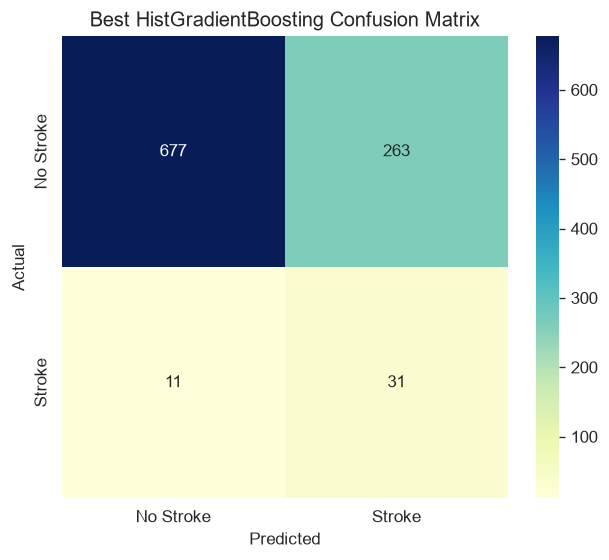


Best ExtraTrees Accuracy: 0.752546
Classification report for Best ExtraTrees:
              precision    recall  f1-score   support

           0     0.9781    0.7585    0.8544       940
           1     0.1028    0.6190    0.1763        42

    accuracy                         0.7525       982
   macro avg     0.5404    0.6888    0.5153       982
weighted avg     0.9406    0.7525    0.8254       982



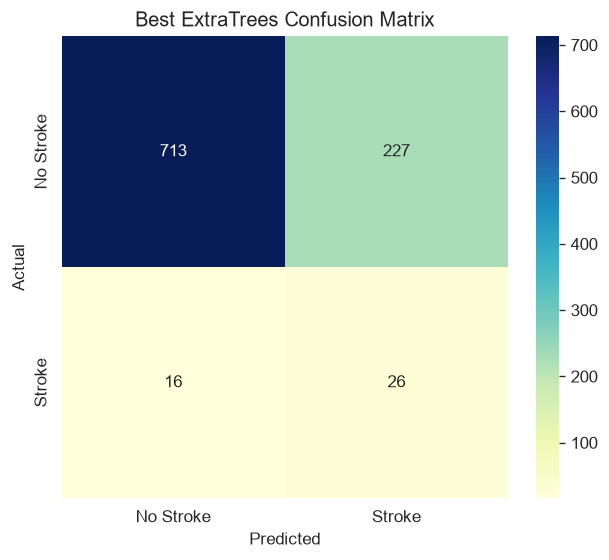


================ THRESHOLD TUNING (chosen on train CV, applied to test) ================

Best RandomForest (threshold=0.576) Accuracy: 0.860489
Classification report for Best RandomForest (threshold=0.576):
              precision    recall  f1-score   support

           0     0.9718    0.8798    0.9235       940
           1     0.1374    0.4286    0.2081        42

    accuracy                         0.8605       982
   macro avg     0.5546    0.6542    0.5658       982
weighted avg     0.9361    0.8605    0.8929       982



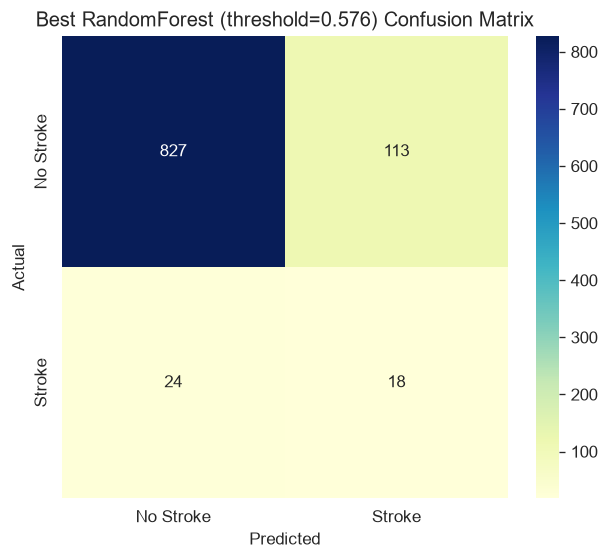


Best SVC (threshold=0.970) Accuracy: 0.882892
Classification report for Best SVC (threshold=0.970):
              precision    recall  f1-score   support

           0     0.9725    0.9032    0.9366       940
           1     0.1651    0.4286    0.2384        42

    accuracy                         0.8829       982
   macro avg     0.5688    0.6659    0.5875       982
weighted avg     0.9380    0.8829    0.9067       982



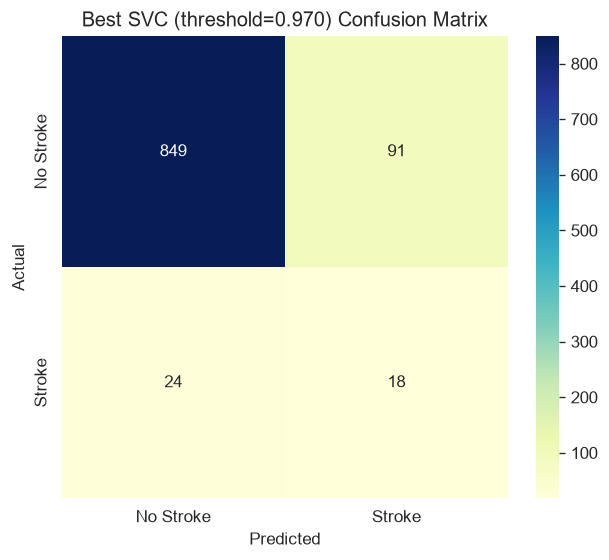


Best KNN (threshold=0.129) Accuracy: 0.895112
Classification report for Best KNN (threshold=0.129):
              precision    recall  f1-score   support

           0     0.9666    0.9223    0.9439       940
           1     0.1412    0.2857    0.1890        42

    accuracy                         0.8951       982
   macro avg     0.5539    0.6040    0.5665       982
weighted avg     0.9313    0.8951    0.9116       982



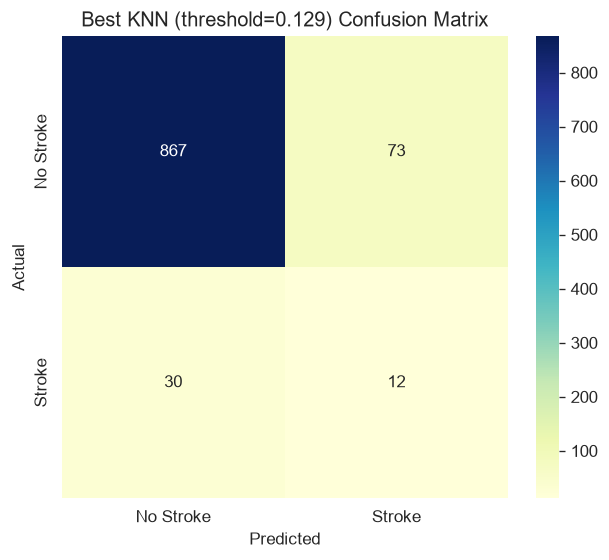


Best GradientBoosting (threshold=0.111) Accuracy: 0.907332
Classification report for Best GradientBoosting (threshold=0.111):
              precision    recall  f1-score   support

           0     0.9680    0.9340    0.9507       940
           1     0.1733    0.3095    0.2222        42

    accuracy                         0.9073       982
   macro avg     0.5707    0.6218    0.5865       982
weighted avg     0.9340    0.9073    0.9196       982



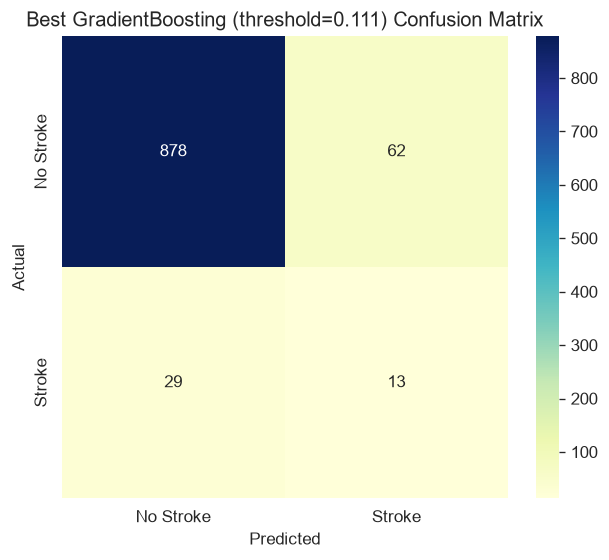


Best LogisticRegression (threshold=0.126) Accuracy: 0.893075
Classification report for Best LogisticRegression (threshold=0.126):
              precision    recall  f1-score   support

           0     0.9707    0.9160    0.9425       940
           1     0.1684    0.3810    0.2336        42

    accuracy                         0.8931       982
   macro avg     0.5696    0.6485    0.5881       982
weighted avg     0.9364    0.8931    0.9122       982



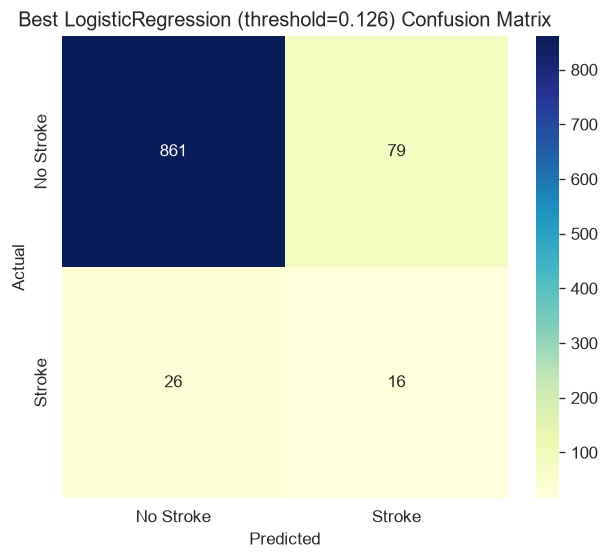


Best HistGradientBoosting (threshold=0.647) Accuracy: 0.839104
Classification report for Best HistGradientBoosting (threshold=0.647):
              precision    recall  f1-score   support

           0     0.9745    0.8543    0.9104       940
           1     0.1329    0.5000    0.2100        42

    accuracy                         0.8391       982
   macro avg     0.5537    0.6771    0.5602       982
weighted avg     0.9385    0.8391    0.8805       982



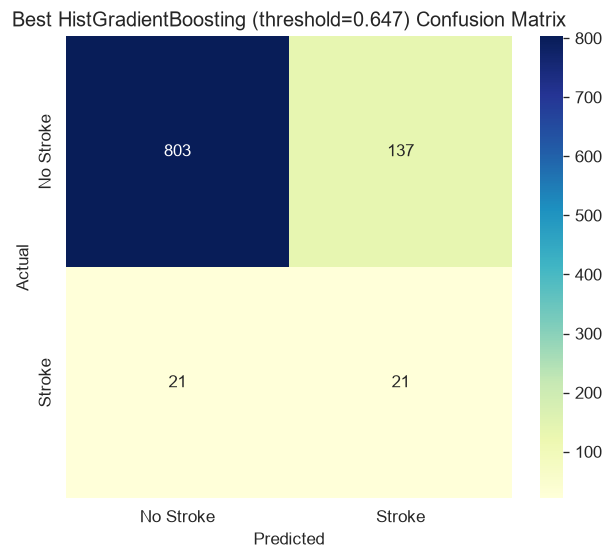


Best ExtraTrees (threshold=0.613) Accuracy: 0.872709
Classification report for Best ExtraTrees (threshold=0.613):
              precision    recall  f1-score   support

           0     0.9733    0.8915    0.9306       940
           1     0.1570    0.4524    0.2331        42

    accuracy                         0.8727       982
   macro avg     0.5652    0.6719    0.5819       982
weighted avg     0.9384    0.8727    0.9008       982



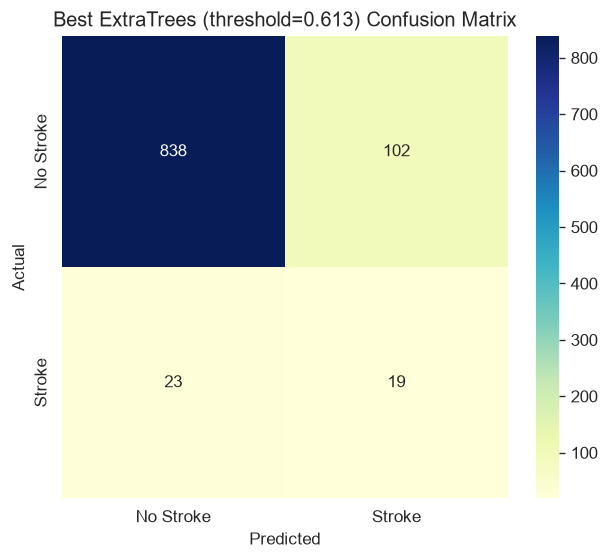


================ FINAL TEST-SET COMPARISON (sorted by ROC-AUC) ================
                                      Model  Accuracy  Balanced_Acc  Precision  Recall     F1  ROC_AUC  PR_AUC
                    Best LogisticRegression    0.9572        0.5000     0.0000  0.0000 0.0000   0.8134  0.2030
  Best LogisticRegression + tuned threshold    0.8931        0.6485     0.1684  0.3810 0.2336   0.8134  0.2030
Best HistGradientBoosting + tuned threshold    0.8391        0.6771     0.1329  0.5000 0.2100   0.8080  0.1549
                  Best HistGradientBoosting    0.7210        0.7292     0.1054  0.7381 0.1845   0.8080  0.1549
                      Best GradientBoosting    0.9572        0.5000     0.0000  0.0000 0.0000   0.8062  0.1374
    Best GradientBoosting + tuned threshold    0.9073        0.6218     0.1733  0.3095 0.2222   0.8062  0.1374
                                   Best SVC    0.7312        0.7231     0.1064  0.7143 0.1852   0.8044  0.2004
                 Best SVC + tun

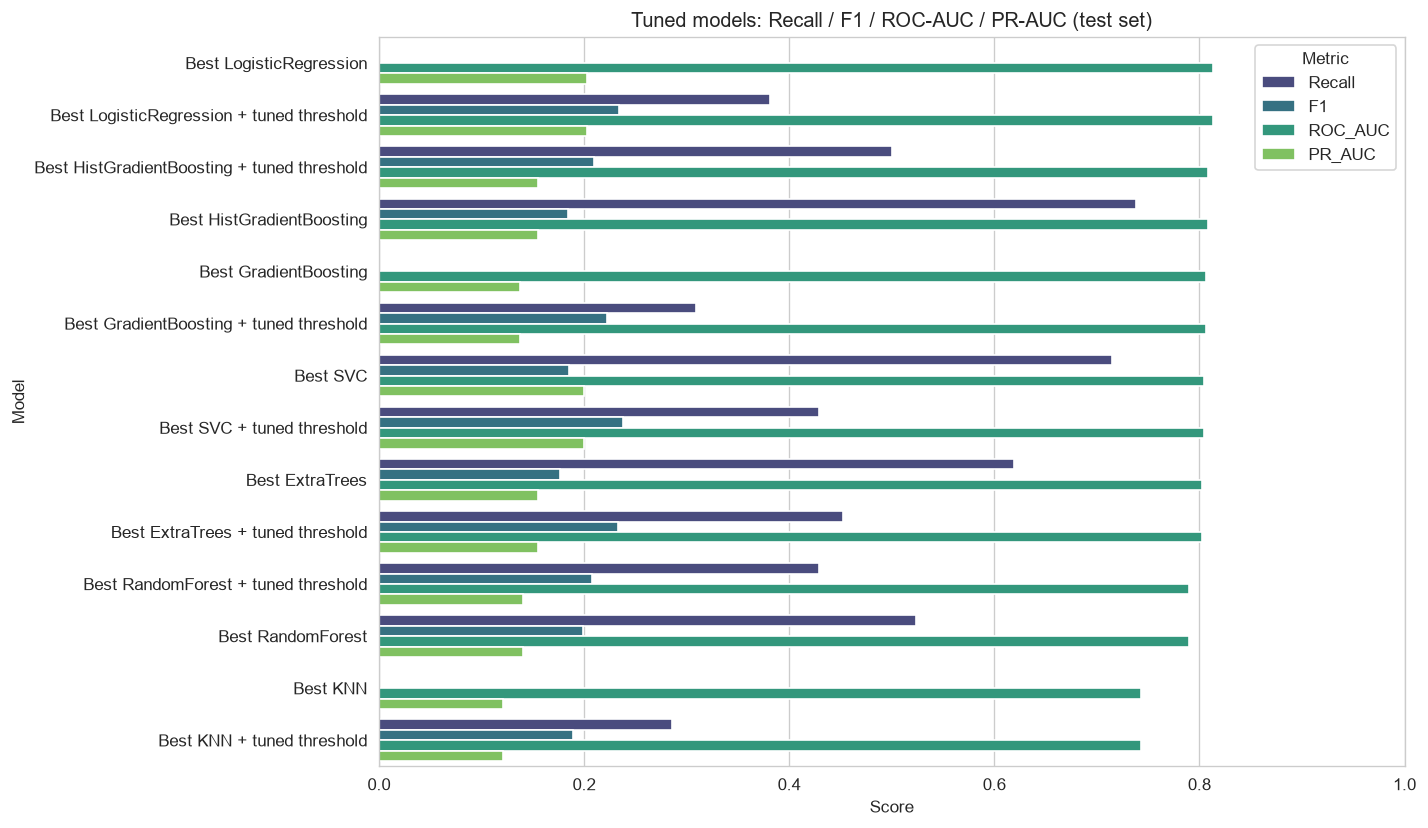


Best tuned model by ROC-AUC: Best LogisticRegression
Best tuned model by F1     : Best SVC + tuned threshold


In [13]:
"""
Stroke Prediction Analysis - Hyperparameter Tuning
---------------------------------------------------
Standalone script: data prep -> GridSearchCV for 5+ models -> evaluation ->
decision-threshold tuning -> comparison table and charts.

Key differences from a generic tuning script, because only ~4% of patients had a stroke:
  * scoring is ROC-AUC (refit), NOT accuracy. Accuracy would pick models that never predict stroke.
  * StratifiedKFold keeps the stroke ratio in every fold.
  * class_weight='balanced' is used wherever the model supports it.
  * Several metrics are tracked during the search (roc_auc, average_precision, f1, recall).

Optional: pip install xgboost lightgbm
"""
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (train_test_split, GridSearchCV, StratifiedKFold,
                                     cross_val_predict)
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, balanced_accuracy_score,
                             precision_recall_curve)
from sklearn.ensemble import (RandomForestClassifier, GradientBoostingClassifier,
                              HistGradientBoostingClassifier, ExtraTreesClassifier)
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression

warnings.filterwarnings('ignore')

# Set QUICK_MODE=True for a fast smoke test (each grid is trimmed to 2 values per parameter).
# Use False for the full search.
QUICK_MODE = False

RND = 42
DATA_PATH = 'healthcare_dataset_stroke.csv'

try:
    from xgboost import XGBClassifier
except ImportError:
    XGBClassifier = None
try:
    from lightgbm import LGBMClassifier
except ImportError:
    LGBMClassifier = None

# ======================================================================
# 1. LOAD & PREPARE DATA
# ======================================================================
data = pd.read_csv(DATA_PATH).drop(columns=['id'])
data = pd.get_dummies(data, drop_first=True, dtype=int)

features = data.drop(columns=['stroke'])
labels = data['stroke']

X_train, X_test, y_train, y_test = train_test_split(
    features, labels, test_size=0.20, random_state=RND, stratify=labels
)
print("Train shape:", X_train.shape, "Test shape:", X_test.shape)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

SPW = (y_train == 0).sum() / (y_train == 1).sum()   # for XGBoost

# ======================================================================
# 2. UTILITIES
# ======================================================================
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RND)
SCORING = {'roc_auc': 'roc_auc', 'pr_auc': 'average_precision', 'f1': 'f1', 'recall': 'recall'}


def get_scores(model, X):
    if hasattr(model, 'predict_proba'):
        return model.predict_proba(X)[:, 1]
    return model.decision_function(X)


def grid_tune(name, estimator, param_grid, Xtr, ytr, cv=CV, scoring=SCORING,
              refit='roc_auc', n_jobs=-1):
    """GridSearchCV tracking several metrics; the best model is chosen by `refit`."""
    gs = GridSearchCV(estimator=estimator, param_grid=param_grid, cv=cv,
                      scoring=scoring, refit=refit, n_jobs=n_jobs, verbose=0)
    t0 = time.time()
    gs.fit(Xtr, ytr)
    i = gs.best_index_
    print(f"\n[{name}] best params: {gs.best_params_}")
    print(f"[{name}] CV  ROC-AUC {gs.cv_results_['mean_test_roc_auc'][i]:.4f} | "
          f"PR-AUC {gs.cv_results_['mean_test_pr_auc'][i]:.4f} | "
          f"F1 {gs.cv_results_['mean_test_f1'][i]:.4f} | "
          f"Recall {gs.cv_results_['mean_test_recall'][i]:.4f}  ({time.time()-t0:.0f}s)")
    return gs


def evaluate_model(model, Xtr, Xte, ytr, yte, name='model', save_cm=None, threshold=None):
    """Fit on train, evaluate on test. If `threshold` is given, it replaces the default 0.5 cutoff."""
    model.fit(Xtr, ytr)
    scores = get_scores(model, Xte)
    if threshold is None:
        preds = model.predict(Xte)
    else:
        preds = (scores >= threshold).astype(int)

    res = {
        'accuracy': accuracy_score(yte, preds),
        'balanced_acc': balanced_accuracy_score(yte, preds),
        'precision': precision_score(yte, preds, zero_division=0),
        'recall': recall_score(yte, preds),
        'f1': f1_score(yte, preds),
        'roc_auc': roc_auc_score(yte, scores),
        'pr_auc': average_precision_score(yte, scores),
        'confusion_matrix': confusion_matrix(yte, preds),
        'report': classification_report(yte, preds, digits=4, zero_division=0),
        'model': model,
    }
    print(f"\n{name} Accuracy: {res['accuracy']:.6f}")
    print(f"Classification report for {name}:\n{res['report']}")

    plt.figure(figsize=(6, 5))
    sns.heatmap(res['confusion_matrix'], annot=True, fmt='d', cmap='YlGnBu',
                xticklabels=['No Stroke', 'Stroke'], yticklabels=['No Stroke', 'Stroke'])
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title(f'{name} Confusion Matrix')
    if save_cm:
        plt.savefig(save_cm, bbox_inches='tight')
    plt.show()
    return res


# ======================================================================
# 3. PARAMETER GRIDS  (class_weight is tuned as a parameter where supported)
# ======================================================================
rf_params = {
    'n_estimators': [100, 300],
    'max_depth': [5, 10, None],
    'min_samples_split': [2, 10],
    'min_samples_leaf': [1, 5],
    'class_weight': ['balanced', 'balanced_subsample'],
}

svc_params = {
    'C': [0.1, 1, 10],
    'gamma': [1, 0.1, 0.01],
    'kernel': ['rbf', 'linear'],
    'class_weight': ['balanced'],
}

knn_params = {
    'n_neighbors': [5, 11, 21, 31],     # larger k is needed on imbalanced data
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan'],
}

gb_params = {
    'n_estimators': [100, 200],
    'learning_rate': [0.01, 0.05, 0.1],
    'max_depth': [2, 3, 5],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 5],
    'subsample': [0.8, 1.0],
}

lr_params = {
    'C': [0.001, 0.01, 0.1, 1, 10, 100],
    'penalty': ['l2'],
    'solver': ['lbfgs'],
    'class_weight': ['balanced', None],
}

hgb_params = {
    'learning_rate': [0.01, 0.05, 0.1],
    'max_depth': [3, 5, None],
    'max_leaf_nodes': [15, 31],
    'min_samples_leaf': [20, 50],
    'l2_regularization': [0.0, 1.0],
    'class_weight': ['balanced'],
}

et_params = {
    'n_estimators': [200, 400],
    'max_depth': [5, 10, None],
    'min_samples_leaf': [1, 5],
    'class_weight': ['balanced', 'balanced_subsample'],
}

# ======================================================================
# 4. TUNE EVERY MODEL
# ======================================================================
tuning_jobs = {
    'RandomForest': (RandomForestClassifier(random_state=RND, n_jobs=1), rf_params),
    'SVC': (SVC(random_state=RND), svc_params),
    'KNN': (KNeighborsClassifier(), knn_params),
    'GradientBoosting': (GradientBoostingClassifier(random_state=RND), gb_params),
    'LogisticRegression': (LogisticRegression(random_state=RND, max_iter=2000), lr_params),
    'HistGradientBoosting': (HistGradientBoostingClassifier(random_state=RND), hgb_params),
    'ExtraTrees': (ExtraTreesClassifier(random_state=RND, n_jobs=1), et_params),
}
if LGBMClassifier is not None:
    tuning_jobs['LightGBM'] = (
        LGBMClassifier(random_state=RND, n_jobs=1, verbose=-1),
        {'n_estimators': [100, 300], 'learning_rate': [0.01, 0.05, 0.1],
         'num_leaves': [7, 15, 31], 'min_child_samples': [20, 50],
         'class_weight': ['balanced']})
if XGBClassifier is not None:
    tuning_jobs['XGBoost'] = (
        XGBClassifier(random_state=RND, n_jobs=1, eval_metric='logloss'),
        {'n_estimators': [100, 300], 'learning_rate': [0.01, 0.05, 0.1],
         'max_depth': [2, 3, 5], 'subsample': [0.8, 1.0],
         'scale_pos_weight': [1, SPW / 2, SPW]})

searches, tuned, cv_rows = {}, {}, []
for name, (est, grid) in tuning_jobs.items():
    if QUICK_MODE:
        grid = {k: v[:2] for k, v in grid.items()}
    n_combos = int(np.prod([len(v) for v in grid.values()]))
    print(f"\n>>> Tuning {name}: {n_combos} combinations x {CV.get_n_splits()} folds")
    gs = grid_tune(name, est, grid, X_train_scaled, y_train)
    searches[name] = gs
    i = gs.best_index_
    cv_rows.append({'Model': name,
                    'CV_ROC_AUC': gs.cv_results_['mean_test_roc_auc'][i],
                    'CV_PR_AUC': gs.cv_results_['mean_test_pr_auc'][i],
                    'CV_F1': gs.cv_results_['mean_test_f1'][i],
                    'CV_Recall': gs.cv_results_['mean_test_recall'][i],
                    'Best_Params': gs.best_params_})

cv_df = pd.DataFrame(cv_rows).sort_values('CV_ROC_AUC', ascending=False).reset_index(drop=True)
pd.set_option('display.width', 220)
pd.set_option('display.max_colwidth', 90)
print("\n================ CROSS-VALIDATED TUNING RESULTS ================")
print(cv_df.drop(columns='Best_Params').round(4).to_string(index=False))

# ======================================================================
# 5. EVALUATE TUNED MODELS ON THE HELD-OUT TEST SET (default 0.5 threshold)
# ======================================================================
eval_results = {}
for name, gs in searches.items():
    eval_results[f'Best {name}'] = evaluate_model(
        gs.best_estimator_, X_train_scaled, X_test_scaled, y_train, y_test,
        name=f'Best {name}', save_cm=f"best_{name.lower()}_cm.png")

# ======================================================================
# 6. DECISION-THRESHOLD TUNING
#    Most models rank strokes well (good AUC) but the 0.5 cutoff is far too high
#    for a 4% event. The threshold is chosen from cross-validated TRAIN predictions
#    (maximising F1), so the test set stays untouched.
# ======================================================================
print("\n================ THRESHOLD TUNING (chosen on train CV, applied to test) ================")
thr_results, thr_values = {}, {}
for name, gs in searches.items():
    est = gs.best_estimator_
    method = 'predict_proba' if hasattr(est, 'predict_proba') else 'decision_function'
    cv_scores = cross_val_predict(est, X_train_scaled, y_train, cv=CV, method=method, n_jobs=-1)
    if method == 'predict_proba':
        cv_scores = cv_scores[:, 1]
    prec, rec, thr = precision_recall_curve(y_train, cv_scores)
    f1s = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
    best_thr = thr[np.argmax(f1s)]
    thr_values[name] = best_thr
    thr_results[f'Best {name} + tuned threshold'] = evaluate_model(
        est, X_train_scaled, X_test_scaled, y_train, y_test,
        name=f'Best {name} (threshold={best_thr:.3f})', threshold=best_thr,
        save_cm=f"best_{name.lower()}_thr_cm.png")

# ======================================================================
# 7. FINAL COMPARISON
# ======================================================================
all_results = {**eval_results, **thr_results}
final_df = pd.DataFrame({
    'Model': list(all_results.keys()),
    'Accuracy': [v['accuracy'] for v in all_results.values()],
    'Balanced_Acc': [v['balanced_acc'] for v in all_results.values()],
    'Precision': [v['precision'] for v in all_results.values()],
    'Recall': [v['recall'] for v in all_results.values()],
    'F1': [v['f1'] for v in all_results.values()],
    'ROC_AUC': [v['roc_auc'] for v in all_results.values()],
    'PR_AUC': [v['pr_auc'] for v in all_results.values()],
}).round(4).sort_values('ROC_AUC', ascending=False).reset_index(drop=True)

print("\n================ FINAL TEST-SET COMPARISON (sorted by ROC-AUC) ================")
print(final_df.to_string(index=False))
final_df.to_csv('tuned_model_comparison.csv', index=False)
cv_df.to_csv('tuning_cv_results.csv', index=False)
print("\nSaved: tuned_model_comparison.csv, tuning_cv_results.csv")

# Charts
melted = final_df.melt(id_vars='Model', value_vars=['Recall', 'F1', 'ROC_AUC', 'PR_AUC'],
                       var_name='Metric', value_name='Score')
plt.figure(figsize=(12, max(7, 0.45 * len(final_df))))
sns.barplot(data=melted, y='Model', x='Score', hue='Metric', palette='viridis',
            order=final_df['Model'])
plt.xlim(0, 1)
plt.title('Tuned models: Recall / F1 / ROC-AUC / PR-AUC (test set)')
plt.tight_layout()
plt.savefig('tuned_models_metrics.png', bbox_inches='tight')
plt.show()

best_auc = final_df.loc[final_df['ROC_AUC'].idxmax(), 'Model']
best_f1 = final_df.loc[final_df['F1'].idxmax(), 'Model']
print(f"\nBest tuned model by ROC-AUC: {best_auc}")
print(f"Best tuned model by F1     : {best_f1}")